# 08 · Chronos-2 LoRA fine-tuning and weather covariates

Fine-tune `amazon/chronos-2` (119M parameters) with LoRA (r = 8, α = 16, lr 1e-5, 200 steps, 56-day context, 7-day horizon), and test whether temperature helps as a covariate.

**Key results**
- Weather matters for Delhi: within-winter temperature anomalies correlate at −0.75 with demand (≈ −1.5 MU per °C).
- Historical GFS forecasts come from Open-Meteo's *Previous Runs* API so each horizon only uses a forecast that existed at the origin (leakage audit included). GFS skill: ~1.3 °C MAE at day 1, worse beyond day 3.
- 2024 validation MAE (all 360 origins): zero-shot with weather 6.93 · LoRA weather 6.88 · **LoRA calendar-only 6.87 MU** — weather adds almost nothing to Chronos-2.
- Feeding *GFS forecasts* as future covariates breaks it (MAE 14.1–14.9, bias +12 MU): the model over-reacts to forecast temperature (+2 °C → +11 to +22 MU), and the frozen base model does the same.
- Found along the way: a pipeline left in training mode (dropout on) makes predictions depend on batch composition by up to 16 MU — always call `.eval()`.

**Decision:** keep Chronos-2 calendar-only; give weather to a separate, small model (notebook 10).

> The 200-step calendar and weather adapters were trained on a GPU from the windows exported here; the adapter is committed under `models/chronos2_calendar_200/` with its `experiment_metadata.json`.

> Paths are relative to `notebooks/`. Outputs are from the original research run; see [`data/README.md`](../data/README.md) for data that must be downloaded.

➡ Next: [09 · LightGBM with GFS forecasts](09_lightgbm_with_gfs.ipynb)

Environment and dependencies

In [1]:
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
import sys

print("Working directory:", Path.cwd())
print("Python:", sys.version.split()[0])

for pkg in [
    "torch", "chronos-forecasting", "transformers",
    "peft", "accelerate", "pandas", "pyarrow"
]:
    try:
        print(f"{pkg:22s} {version(pkg)}")
    except PackageNotFoundError:
        print(f"{pkg:22s} NOT INSTALLED")

try:
    import torch
    print("\nCUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
except ImportError:
    pass

Working directory: notebooks
Python: 3.12.12
torch                  2.15.0
chronos-forecasting    2.3.2
transformers           5.23.0
peft                   NOT INSTALLED
accelerate             1.16.0
pandas                 3.1.1
pyarrow                26.0.1

CUDA available: False


Inspect the prepared data

In [2]:
import pandas as pd

data_dir = Path("../data/processed")

print("Data directory:", data_dir.resolve())
assert data_dir.is_dir(), "Processed data directory not found"

print("\nAvailable files:")
for path in sorted(data_dir.iterdir()):
    print(" ", path.name)

dev_path = data_dir / "gridpulse_v2_development.csv"
assert dev_path.is_file(), f"Missing: {dev_path}"

dev = pd.read_csv(dev_path)

print("\nDataset shape:", dev.shape)
print("\nColumns and data types:")
print(dev.dtypes.to_string())

print("\nFirst records:")
display(dev.head(3))

print("\nLast records:")
display(dev.tail(3))

Data directory: data\processed

Available files:
  delhi_energy_clean.csv
  delhi_energy_conflicts.csv
  foundation_eval_2021_28d.parquet
  foundation_walkforward_2019.parquet
  foundation_walkforward_2021.parquet
  gridpulse_eval_176_v1.parquet
  gridpulse_features_v1.parquet
  gridpulse_v2_development.csv
  gridpulse_v2_external_test.csv
  seasonal_naive_predictions.csv
  timesfm_validation_176_v1.parquet
  trend_naive_predictions.csv
  walkforward_fold_a.parquet
  walkforward_fold_b.parquet
  xgb_validation_v01.parquet

Dataset shape: (2193, 4)

Columns and data types:
date                     str
energy_met_mu        float64
max_demand_met_mw    float64
energy_missing          bool

First records:


,date,energy_met_mu,max_demand_met_mw,energy_missing
0,2018-12-31,69.0,4292.0,False
1,2019-01-01,69.6,4336.0,False
2,2019-01-02,69.0,4183.0,False



Last records:


,date,energy_met_mu,max_demand_met_mw,energy_missing
2190,2024-12-29,78.94,4697.0,False
2191,2024-12-30,83.39,4978.0,False
2192,2024-12-31,85.18,5123.0,False


Inspect existing feature columns

In [3]:
features_path = data_dir / "gridpulse_features_v1.parquet"

features = pd.read_parquet(features_path)

print("Shape:", features.shape)

print("\nAvailable columns:")
for col in features.columns:
    print(f"  {col}")

print("\nSample:")
display(features.head(3))

Shape: (14987, 40)

Available columns:
  lag_1
  lag_2
  lag_3
  lag_4
  lag_5
  lag_6
  lag_7
  lag_8
  lag_9
  lag_10
  lag_11
  lag_12
  lag_13
  lag_14
  lag_15
  lag_16
  lag_17
  lag_18
  lag_19
  lag_20
  lag_21
  lag_22
  lag_23
  lag_24
  lag_25
  lag_26
  lag_27
  lag_28
  rolling_mean_7
  rolling_std_7
  rolling_mean_28
  rolling_std_28
  origin
  target_date
  horizon
  day_of_week
  month
  day_of_year
  target
  split

Sample:


,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,...,rolling_mean_28,rolling_std_28,origin,target_date,horizon,day_of_week,month,day_of_year,target,split
0,79.2,83.6,83.4,78.4,77.1,74.0,71.1,76.5,76.3,78.6,...,71.317857,7.436736,2013-04-27,2013-04-28,1,6,4,118,74.5,development
1,79.2,83.6,83.4,78.4,77.1,74.0,71.1,76.5,76.3,78.6,...,71.317857,7.436736,2013-04-27,2013-04-29,2,0,4,119,81.6,development
2,79.2,83.6,83.4,78.4,77.1,74.0,71.1,76.5,76.3,78.6,...,71.317857,7.436736,2013-04-27,2013-04-30,3,1,4,120,86.1,development


Inspect pre-2024 demand data

In [4]:
dev["date"] = pd.to_datetime(dev["date"])

train = dev.loc[dev["date"] < "2024-01-01"].copy()
train = train.sort_values("date")

print("Training rows:", len(train))
print("Date range:", train["date"].min(), "to", train["date"].max())

print("\nMissing energy readings:",
      train["energy_met_mu"].isna().sum())

print("Flagged missing readings:",
      train["energy_missing"].sum())

print("Duplicate dates:",
      train["date"].duplicated().sum())

print("Missing calendar dates:",
      len(pd.date_range(train["date"].min(),
                        train["date"].max()).difference(train["date"])))

Training rows: 1827
Date range: 2018-12-31 00:00:00 to 2023-12-31 00:00:00

Missing energy readings: 70
Flagged missing readings: 70
Duplicate dates: 0
Missing calendar dates: 0


Retrieve historical weather

In [5]:
import requests
import pandas as pd
from pathlib import Path

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 28.6139,
    "longitude": 77.2090,
    "start_date": "2018-12-31",
    "end_date": "2023-12-31",
    "daily": ",".join([
        "temperature_2m_max",
        "temperature_2m_min",
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "apparent_temperature_max",
        "precipitation_sum",
    ]),
    "timezone": "Asia/Kolkata",
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

weather_train = pd.DataFrame(response.json()["daily"])
weather_train = weather_train.rename(columns={"time": "date"})
weather_train["date"] = pd.to_datetime(weather_train["date"])

print("Weather shape:", weather_train.shape)
print("Date range:", weather_train["date"].min(), weather_train["date"].max())
display(weather_train.head())

Weather shape: (1827, 7)
Date range: 2018-12-31 00:00:00 2023-12-31 00:00:00


,date,temperature_2m_max,temperature_2m_min,temperature_2m_mean,relative_humidity_2m_mean,apparent_temperature_max,precipitation_sum
0,2018-12-31,20.7,5.3,12.3,70,17.9,0.0
1,2019-01-01,20.2,5.8,12.7,71,18.7,0.0
2,2019-01-02,21.1,7.5,14.1,71,19.8,0.0
3,2019-01-03,20.7,7.4,13.4,70,17.9,0.0
4,2019-01-04,18.8,6.9,12.6,70,17.1,0.0


Join weather with electricity demand

In [6]:
train_weather = train.merge(
    weather_train,
    on="date",
    how="left",
    validate="one_to_one",
)

weather_cols = [
    c for c in weather_train.columns if c != "date"
]

print("Merged shape:", train_weather.shape)

print("\nMissing values:")
print(train_weather[
    ["energy_met_mu"] + weather_cols
].isna().sum())

print("\nSample:")
display(
    train_weather[
        ["date", "energy_met_mu"] + weather_cols
    ].head()
)

Merged shape: (1827, 10)

Missing values:
energy_met_mu                70
temperature_2m_max            0
temperature_2m_min            0
temperature_2m_mean           0
relative_humidity_2m_mean     0
apparent_temperature_max      0
precipitation_sum             0
dtype: int64

Sample:


,date,energy_met_mu,temperature_2m_max,temperature_2m_min,temperature_2m_mean,relative_humidity_2m_mean,apparent_temperature_max,precipitation_sum
0,2018-12-31,69.0,20.7,5.3,12.3,70,17.9,0.0
1,2019-01-01,69.6,20.2,5.8,12.7,71,18.7,0.0
2,2019-01-02,69.0,21.1,7.5,14.1,71,19.8,0.0
3,2019-01-03,68.3,20.7,7.4,13.4,70,17.9,0.0
4,2019-01-04,73.9,18.8,6.9,12.6,70,17.1,0.0


Prepare calendar features

In [7]:
import numpy as np

train_weather = train_weather.sort_values("date").reset_index(drop=True)

# Cyclical calendar encoding
day_of_year = train_weather["date"].dt.dayofyear
day_of_week = train_weather["date"].dt.dayofweek

train_weather["year_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
train_weather["year_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)

train_weather["week_sin"] = np.sin(2 * np.pi * day_of_week / 7)
train_weather["week_cos"] = np.cos(2 * np.pi * day_of_week / 7)

calendar_cols = ["year_sin", "year_cos", "week_sin", "week_cos"]

print("Weather:", weather_cols)
print("Calendar:", calendar_cols)

display(train_weather.tail(3))

Weather: ['temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'relative_humidity_2m_mean', 'apparent_temperature_max', 'precipitation_sum']
Calendar: ['year_sin', 'year_cos', 'week_sin', 'week_cos']


,date,energy_met_mu,max_demand_met_mw,energy_missing,temperature_2m_max,temperature_2m_min,temperature_2m_mean,relative_humidity_2m_mean,apparent_temperature_max,precipitation_sum,year_sin,year_cos,week_sin,week_cos
1824,2023-12-29,80.03,4813.0,False,20.2,8.2,13.3,87,20.6,0.0,-0.038696,0.999251,-0.433884,-0.900969
1825,2023-12-30,75.18,4441.0,False,19.0,8.9,12.5,90,19.1,0.0,-0.021501,0.999769,-0.974928,-0.222521
1826,2023-12-31,73.04,4600.0,False,18.7,7.0,12.7,84,18.4,0.0,-0.004301,0.999991,-0.781831,0.623490


Construct Chronos-2 examples

In [8]:
CONTEXT = 56
HORIZON = 7

chronos_train = []
train_origins = []

for end in range(CONTEXT, len(train_weather) - HORIZON + 1):

    past = train_weather.iloc[end - CONTEXT:end]
    future = train_weather.iloc[end:end + HORIZON]

    # Require complete demand history and training targets
    if past["energy_met_mu"].isna().any():
        continue

    if future["energy_met_mu"].isna().any():
        continue

    # Calendar continuity
    dates = train_weather.iloc[end - CONTEXT:end + HORIZON]["date"]
    if not dates.diff().dropna().eq(pd.Timedelta(days=1)).all():
        continue

    example = {
        "target": past["energy_met_mu"].to_numpy(dtype=np.float32),
        "past_covariates": {
            col: past[col].to_numpy(dtype=np.float32)
            for col in weather_cols + calendar_cols
        },
        "future_covariates": {
            col: future[col].to_numpy(dtype=np.float32)
            for col in calendar_cols
        },
    }

    chronos_train.append(example)
    train_origins.append(past["date"].iloc[-1])

print("Training examples:", len(chronos_train))
print("First origin:", train_origins[0] if train_origins else None)
print("Last origin:", train_origins[-1] if train_origins else None)

if chronos_train:
    example = chronos_train[0]
    print("Target shape:", example["target"].shape)
    print("Past weather shape:",
          example["past_covariates"]["precipitation_sum"].shape)
    print("Future calendar shape:",
          example["future_covariates"]["week_sin"].shape)

Training examples: 733
First origin: 2019-03-24 00:00:00
Last origin: 2023-12-24 00:00:00
Target shape: (56,)
Past weather shape: (56,)
Future calendar shape: (7,)


Build supervised Chronos-2 training records

In [9]:
chronos_fit_inputs = []

for origin in train_origins:
    end = train_weather.index[
        train_weather["date"].eq(origin)
    ][0] + 1

    block = train_weather.iloc[end - CONTEXT:end + HORIZON]

    assert len(block) == CONTEXT + HORIZON
    assert block["energy_met_mu"].notna().all()

    # Full sequence: 56-day context + 7 training labels
    target = block["energy_met_mu"].to_numpy(dtype=np.float32)

    covariates = {}

    # Weather is only observed in the historical context
    for col in weather_cols:
        covariates[col] = np.concatenate([
            block[col].iloc[:CONTEXT].to_numpy(dtype=np.float32),
            np.full(HORIZON, np.nan, dtype=np.float32),
        ])

    # Calendar is known for all 63 days
    for col in calendar_cols:
        covariates[col] = block[col].to_numpy(dtype=np.float32)

    chronos_fit_inputs.append({
        "target": target,
        "past_covariates": covariates,
        "future_covariates": {
            col: block[col].iloc[-HORIZON:].to_numpy(dtype=np.float32)
            for col in calendar_cols
        },
    })

print("Training records:", len(chronos_fit_inputs))
print("Target length:", len(chronos_fit_inputs[0]["target"]))
print("Weather covariates:", len(weather_cols))
print("Calendar covariates:", len(calendar_cols))

assert len(chronos_fit_inputs) == 733
assert all(
    len(item["target"]) == 63
    for item in chronos_fit_inputs
)

Training records: 733
Target length: 63
Weather covariates: 6
Calendar covariates: 4


Verify Chronos-2 preprocessing and training batches

In [10]:
from chronos.chronos2.dataset import Chronos2Dataset, DatasetMode

# Use one training record for a lightweight structural test
test_dataset = Chronos2Dataset(
    inputs=chronos_fit_inputs[:1],
    context_length=CONTEXT,
    prediction_length=HORIZON,
    batch_size=11,  # 1 demand + 6 weather + 4 calendar series
    output_patch_size=16,
    min_past=CONTEXT,
    mode=DatasetMode.TRAIN,
)

batch = next(iter(test_dataset))

for key, value in batch.items():
    if hasattr(value, "shape"):
        print(f"{key:22s} {tuple(value.shape)}")
    else:
        print(f"{key:22s} {value}")

print("\nDemand context:")
print(batch["context"][0, -5:])

print("\nFuture demand labels:")
print(batch["future_target"][0])

print("\nFuture weather masked:",
      batch["future_covariates"][1:7].isnan().all().item())

print("Future calendar available:",
      batch["future_covariates"][7:11].isfinite().all().item())

context                (11, 56)
future_target          (11, 7)
future_covariates      (11, 7)
group_ids              (11,)
num_output_patches     1

Demand context:
tensor([60.1000, 46.1000, 54.4000, 57.9000, 58.2000])

Future demand labels:
tensor([61.7000, 64.3000, 65.9000, 67.4000, 71.8000, 73.9000, 69.1000])

Future weather masked: True
Future calendar available: True


*Initialize Chronos-2*

Install PEFT in the active notebook environment

In [11]:
import subprocess
import sys

subprocess.run(
    ["uv", "pip", "install", "--python", sys.executable, "peft"],
    check=True
)

import peft
print("PEFT version:", peft.__version__)

PEFT version: 0.22.0


Load the pretrained Chronos-2 model

In [12]:
import torch
from chronos import Chronos2Pipeline

BASE_MODEL = "amazon/chronos-2"

pipeline = Chronos2Pipeline.from_pretrained(
    BASE_MODEL,
    device_map="cpu",
    torch_dtype=torch.float32,
)

print("Model:", BASE_MODEL)
print("Device:", pipeline.model.device)
print("Context capacity:", pipeline.model_context_length)
print("Output patch size:", pipeline.model_output_patch_size)
print("Maximum prediction length:", pipeline.model_prediction_length)

total_params = sum(p.numel() for p in pipeline.model.parameters())
print(f"Parameters: {total_params:,}")

Model: amazon/chronos-2
Device: cpu
Context capacity: 8192
Output patch size: 16
Maximum prediction length: 1024
Parameters: 119,477,664


Test one weather-aware forecast

In [13]:
example = chronos_train[0]

pipeline.model.eval()

with torch.inference_mode():
    predictions = pipeline.predict(
        inputs=[example],
        prediction_length=HORIZON,
        context_length=CONTEXT,
        batch_size=16,
    )

print("Prediction shape:", predictions[0].shape)
print("Quantiles:", pipeline.quantiles)

median_idx = pipeline.quantiles.index(0.5)

forecast = (
    predictions[0][0, median_idx, :]
    .cpu()
    .numpy()
)

print("7-day forecast (MU):", forecast.round(2))

Prediction shape: torch.Size([1, 21, 7])
Quantiles: [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]
7-day forecast (MU): [59.11 60.3  59.91 59.3  60.03 57.87 56.15]


Compare the forecast with actual training-period demand

In [14]:
origin = train_origins[0]

actual = train_weather.loc[
    (train_weather["date"] > origin)
    & (train_weather["date"] <= origin + pd.Timedelta(days=7)),
    ["date", "energy_met_mu"]
].copy()

actual["forecast_mu"] = forecast
actual["absolute_error"] = (
    actual["energy_met_mu"] - actual["forecast_mu"]
).abs()

display(actual)

print(
    "Smoke-test MAE:",
    round(actual["absolute_error"].mean(), 3),
    "MU"
)

,date,energy_met_mu,forecast_mu,absolute_error
84,2019-03-25,61.7,59.111195,2.588805
85,2019-03-26,64.3,60.297558,4.002442
86,2019-03-27,65.9,59.909966,5.990034
87,2019-03-28,67.4,59.296501,8.103499
88,2019-03-29,71.8,60.031868,11.768132
89,2019-03-30,73.9,57.866920,16.033080
90,2019-03-31,69.1,56.152721,12.947279


Smoke-test MAE: 8.776 MU


**Prepare for GPU fine-tuning**

Verify supervision masks

In [15]:
batch = next(iter(test_dataset))

target_mask = torch.isfinite(batch["future_target"])

print("Group IDs:", batch["group_ids"].tolist())
print("Valid future labels per series:")
print(target_mask.sum(dim=1).tolist())

assert target_mask[0].sum().item() == HORIZON
assert target_mask[1:].sum().item() == 0

print("\nDemand labels present; covariate labels masked.")

Group IDs: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Valid future labels per series:
[7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Demand labels present; covariate labels masked.


Save the prepared training data

In [16]:
import json

out_path = data_dir / "gridpulse_chronos2_train_v1.parquet"

assert train_weather["date"].max() < pd.Timestamp("2024-01-01")

train_weather.to_parquet(out_path, index=False)

config = {
    "base_model": "amazon/chronos-2",
    "context_length": CONTEXT,
    "prediction_length": HORIZON,
    "weather_columns": weather_cols,
    "calendar_columns": calendar_cols,
    "training_windows": len(chronos_fit_inputs),
    "seed": 42,
    "training_end": "2023-12-31",
}

config_path = data_dir / "gridpulse_chronos2_config_v1.json"
config_path.write_text(json.dumps(config, indent=2), encoding="utf-8")

print("Saved:", out_path)
print("Saved:", config_path)

Saved: ..\data\processed\gridpulse_chronos2_train_v1.parquet
Saved: ..\data\processed\gridpulse_chronos2_config_v1.json


Export the supervised windows

In [17]:
import pickle

windows_path = data_dir / "gridpulse_chronos2_windows_v1.pkl"

with windows_path.open("wb") as f:
    pickle.dump(chronos_fit_inputs, f, protocol=pickle.HIGHEST_PROTOCOL)

print("Saved:", windows_path)
print("Size:", round(windows_path.stat().st_size / 1024**2, 2), "MB")
print("Examples:", len(chronos_fit_inputs))

Saved: ..\data\processed\gridpulse_chronos2_windows_v1.pkl
Size: 2.31 MB
Examples: 733


Record the exact training configuration

In [18]:
training_config = {
    **config,
    "finetune_mode": "lora",
    "lora_rank": 8,
    "lora_alpha": 16,
    "learning_rate": 1e-5,
    "batch_size": 11,
    "num_steps": 20,
    "min_past": 56,
    "train_windows_file": windows_path.name,
    "chronos_version": "2.3.2",
}

training_config_path = (
    data_dir / "gridpulse_chronos2_training_config_v1.json"
)

training_config_path.write_text(
    json.dumps(training_config, indent=2),
    encoding="utf-8",
)

print(training_config_path)

..\data\processed\gridpulse_chronos2_training_config_v1.json


## Why weather? Demand-change events and temperature

In [19]:
import pandas as pd
import numpy as np

analysis = train_weather.sort_values("date").copy()

# Compare demand against the same weekday, 7 days earlier
analysis["demand_previous_week"] = (
    analysis["energy_met_mu"].shift(7)
)

analysis["demand_change_mu"] = (
    analysis["energy_met_mu"] - analysis["demand_previous_week"]
)

analysis["demand_change_pct"] = (
    100 * analysis["demand_change_mu"]
    / analysis["demand_previous_week"]
)

cols = [
    "date",
    "energy_met_mu",
    "demand_change_mu",
    "demand_change_pct",
    "temperature_2m_max",
    "apparent_temperature_max",
    "relative_humidity_2m_mean",
    "precipitation_sum",
]

print("Biggest demand increases:")
display(
    analysis.nlargest(10, "demand_change_mu")[cols].round(2)
)

print("\nBiggest demand decreases:")
display(
    analysis.nsmallest(10, "demand_change_mu")[cols].round(2)
)

Biggest demand increases:


,date,energy_met_mu,demand_change_mu,demand_change_pct,temperature_2m_max,apparent_temperature_max,relative_humidity_2m_mean,precipitation_sum
1275,2022-06-28,153.50,45.80,42.53,41.2,44.3,56,0.9
891,2021-06-09,122.80,41.00,50.12,41.5,43.7,38,0.0
1276,2022-06-29,152.80,40.50,36.06,42.1,44.9,58,0.0
1274,2022-06-27,145.40,40.40,38.48,38.8,43.9,54,0.0
892,2021-06-10,128.60,40.30,45.64,38.1,42.7,58,0.0
205,2019-07-24,130.40,38.80,42.36,36.7,43.7,74,6.8
890,2021-06-08,113.70,38.40,51.00,40.9,41.1,39,0.0
115,2019-04-25,111.40,37.00,49.73,39.3,41.3,36,0.0
1285,2022-07-08,149.30,36.50,32.36,36.9,42.1,63,0.1
1695,2023-08-22,147.93,35.22,31.25,35.4,42.9,79,12.6



Biggest demand decreases:


,date,energy_met_mu,demand_change_mu,demand_change_pct,temperature_2m_max,apparent_temperature_max,relative_humidity_2m_mean,precipitation_sum
1267,2022-06-20,105.00,-45.30,-30.14,32.7,36.4,73,0.1
1240,2022-05-24,91.10,-41.70,-31.40,33.4,36.2,64,0.0
169,2019-06-18,99.30,-39.80,-28.61,36.1,39.2,55,0.5
1611,2023-05-30,97.73,-37.22,-27.58,34.2,38.1,65,0.1
1266,2022-06-19,98.60,-37.00,-27.29,32.0,35.3,82,9.9
1268,2022-06-21,107.70,-36.50,-25.31,32.1,36.5,72,9.3
198,2019-07-17,91.60,-36.20,-28.33,30.8,36.6,85,14.8
1356,2022-09-17,98.00,-35.80,-26.76,33.8,37.5,78,0.8
1241,2022-05-25,100.30,-35.70,-26.25,33.3,36.5,60,0.0
199,2019-07-18,100.60,-34.90,-25.76,32.4,37.8,82,12.8


In [20]:
# Top 10 increases and decreases
increases = analysis.nlargest(10, "demand_change_mu").copy()
decreases = analysis.nsmallest(10, "demand_change_mu").copy()

events = pd.concat([
    increases.assign(event_type="Increase"),
    decreases.assign(event_type="Decrease")
])

event_windows = []

for _, event in events.iterrows():
    event_date = event["date"]

    window = analysis.loc[
        analysis["date"].between(
            event_date - pd.Timedelta(days=2),
            event_date + pd.Timedelta(days=2)
        )
    ].copy()

    window["event_date"] = event_date
    window["event_type"] = event["event_type"]
    window["relative_day"] = (
        window["date"] - event_date
    ).dt.days

    event_windows.append(window)

event_detail = pd.concat(event_windows, ignore_index=True)

display(
    event_detail[
        [
            "event_type", "event_date", "relative_day",
            "date", "energy_met_mu",
            "temperature_2m_max",
            "apparent_temperature_max",
            "relative_humidity_2m_mean",
            "precipitation_sum"
        ]
    ].round(2)
)

,event_type,event_date,relative_day,date,energy_met_mu,temperature_2m_max,apparent_temperature_max,relative_humidity_2m_mean,precipitation_sum
0,Increase,2022-06-28,-2,2022-06-26,127.7,39.2,42.4,51,0.0
1,Increase,2022-06-28,-1,2022-06-27,145.4,38.8,43.9,54,0.0
2,Increase,2022-06-28,0,2022-06-28,153.5,41.2,44.3,56,0.9
3,Increase,2022-06-28,1,2022-06-29,152.8,42.1,44.9,58,0.0
4,Increase,2022-06-28,2,2022-06-30,123.5,31.3,36.1,79,1.4
...,...,...,...,...,...,...,...,...,...
95,Decrease,2019-07-18,-2,2019-07-16,108.0,29.2,34.6,89,20.6
96,Decrease,2019-07-18,-1,2019-07-17,91.6,30.8,36.6,85,14.8
97,Decrease,2019-07-18,0,2019-07-18,100.6,32.4,37.8,82,12.8
98,Decrease,2019-07-18,1,2019-07-19,108.6,33.3,41.6,79,6.7


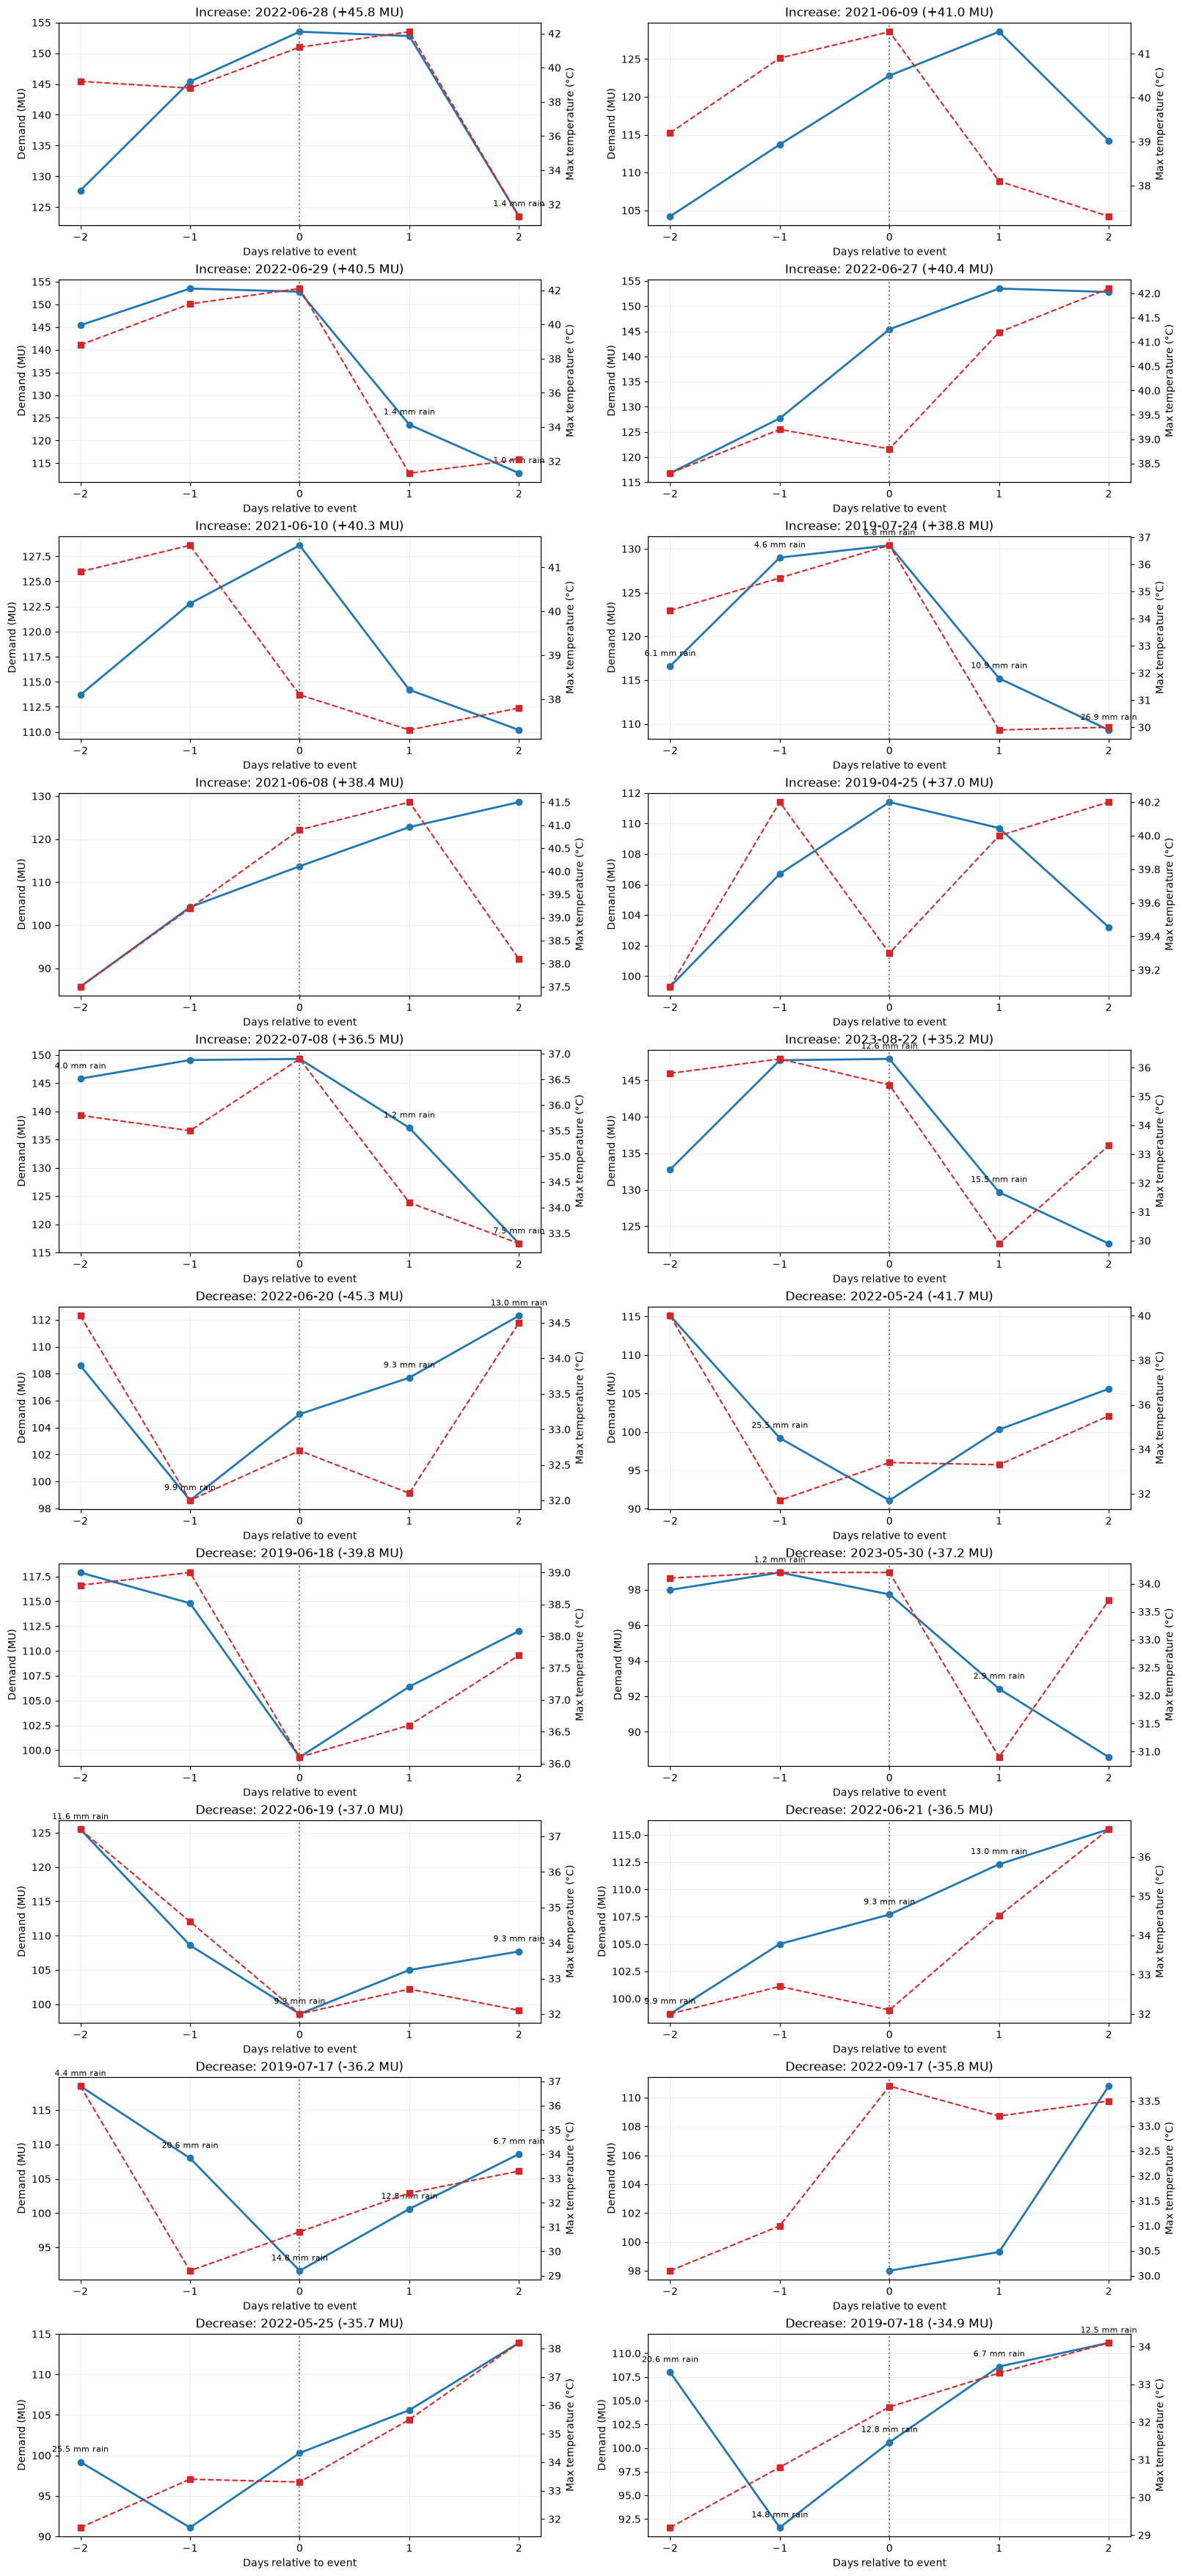

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    10, 2, figsize=(16, 35),
    constrained_layout=True
)

for ax, (_, event) in zip(axes.flat, events.iterrows()):
    window = event_detail.loc[
        event_detail["event_date"].eq(event["date"])
    ].copy()

    x = window["relative_day"]

    ax.plot(
        x, window["energy_met_mu"],
        marker="o", linewidth=2,
        label="Demand (MU)"
    )

    temp_ax = ax.twinx()
    temp_ax.plot(
        x, window["temperature_2m_max"],
        marker="s", linestyle="--",
        color="tab:red", label="Temperature (°C)"
    )

    # Rainfall shown as values beneath observations
    for _, row in window.iterrows():
        if row["precipitation_sum"] >= 1:
            ax.annotate(
                f'{row["precipitation_sum"]:.1f} mm rain',
                (row["relative_day"], row["energy_met_mu"]),
                xytext=(0, 10),
                textcoords="offset points",
                fontsize=8,
                ha="center"
            )

    ax.axvline(0, color="gray", linestyle=":")
    ax.set_xticks([-2, -1, 0, 1, 2])
    ax.set_xlabel("Days relative to event")
    ax.set_ylabel("Demand (MU)")
    temp_ax.set_ylabel("Max temperature (°C)")
    ax.set_title(
        f'{event["event_type"]}: '
        f'{event["date"].date()} '
        f'({event["demand_change_mu"]:+.1f} MU)'
    )
    ax.grid(alpha=0.2)

plt.show()

In [22]:
analysis = analysis.sort_values("date").copy()

variables = [
    "temperature_2m_max",
    "temperature_2m_mean",
    "apparent_temperature_max",
    "relative_humidity_2m_mean",
    "precipitation_sum",
]

analysis["demand_delta"] = analysis["energy_met_mu"].diff()

for col in variables:
    analysis[f"{col}_delta"] = analysis[col].diff()

correlations = {
    col: analysis["demand_delta"].corr(analysis[f"{col}_delta"])
    for col in variables
}

display(
    pd.Series(correlations, name="Correlation with daily demand change")
    .sort_values(ascending=False)
    .to_frame()
    .round(3)
)

,Correlation with daily demand change
temperature_2m_mean,0.352
temperature_2m_max,0.301
apparent_temperature_max,0.254
precipitation_sum,-0.140
relative_humidity_2m_mean,-0.229


In [23]:
analysis["month"] = analysis["date"].dt.month

seasons = {
    "Winter (Dec-Feb)": [12, 1, 2],
    "Pre-monsoon (Mar-Jun)": [3, 4, 5, 6],
    "Monsoon (Jul-Sep)": [7, 8, 9],
    "Post-monsoon (Oct-Nov)": [10, 11],
}

rows = []

for season, months in seasons.items():
    subset = analysis[analysis["month"].isin(months)]

    rows.append({
        "Season": season,
        "Days": subset["demand_delta"].notna().sum(),
        "Mean temp": subset["demand_delta"].corr(
            subset["temperature_2m_mean_delta"]
        ),
        "Max temp": subset["demand_delta"].corr(
            subset["temperature_2m_max_delta"]
        ),
        "Rainfall": subset["demand_delta"].corr(
            subset["precipitation_sum_delta"]
        ),
    })

seasonal_corr = pd.DataFrame(rows).set_index("Season")

display(seasonal_corr.round(3))

,Days,Mean temp,Max temp,Rainfall
Season,,,,
Winter (Dec-Feb),430,-0.174,-0.080,-0.061
Pre-monsoon (Mar-Jun),574,0.483,0.401,-0.079
Monsoon (Jul-Sep),412,0.539,0.428,-0.199
Post-monsoon (Oct-Nov),281,0.172,0.038,-0.107


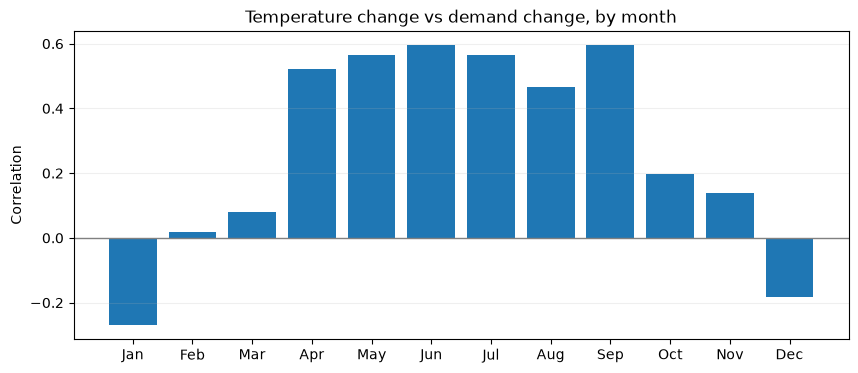

In [24]:
monthly_corr = (
    analysis.groupby("month")
    .apply(
        lambda x: x["demand_delta"].corr(
            x["temperature_2m_mean_delta"]
        ),
        include_groups=False,
    )
)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))

ax.bar(monthly_corr.index, monthly_corr.values)
ax.axhline(0, color="gray", linewidth=1)

ax.set_xticks(range(1, 13))
ax.set_xticklabels([
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

ax.set_ylabel("Correlation")
ax.set_title("Temperature change vs demand change, by month")
ax.grid(axis="y", alpha=0.2)

plt.show()

In [25]:
winter = analysis.loc[
    analysis["date"].dt.month.isin([12, 1, 2])
].copy()

winter = winter.dropna(
    subset=["energy_met_mu", "temperature_2m_min"]
)

winter["winter_demand_avg"] = (
    winter.groupby(winter["date"].dt.year)["energy_met_mu"]
    .transform("mean")
)

winter["above_winter_avg_pct"] = (
    100 * (
        winter["energy_met_mu"] / winter["winter_demand_avg"] - 1
    )
)

cols = [
    "date",
    "temperature_2m_min",
    "temperature_2m_mean",
    "energy_met_mu",
    "above_winter_avg_pct",
]

print("20 coldest winter days:")
display(
    winter.nsmallest(20, "temperature_2m_min")[cols]
    .round(2)
)

print("\nWinter temperature-demand correlations:")
for temp_col in [
    "temperature_2m_min",
    "temperature_2m_mean",
    "temperature_2m_max"
]:
    print(
        temp_col,
        round(winter[temp_col].corr(winter["energy_met_mu"]), 3)
    )

20 coldest winter days:


,date,temperature_2m_min,temperature_2m_mean,energy_met_mu,above_winter_avg_pct
365,2019-12-31,1.9,7.6,85.50,24.86
362,2019-12-28,2.9,6.7,80.40,17.41
366,2020-01-01,2.9,10.0,83.50,20.97
364,2019-12-30,3.2,6.9,85.80,25.30
1479,2023-01-18,3.2,9.2,85.51,16.69
361,2019-12-27,3.3,7.3,82.00,19.75
1478,2023-01-17,3.4,9.0,84.73,15.63
732,2021-01-01,3.5,10.5,77.00,12.97
1477,2023-01-16,3.6,9.0,83.98,14.60
363,2019-12-29,3.7,7.3,78.00,13.91



Winter temperature-demand correlations:
temperature_2m_min -0.602
temperature_2m_mean -0.663
temperature_2m_max -0.61


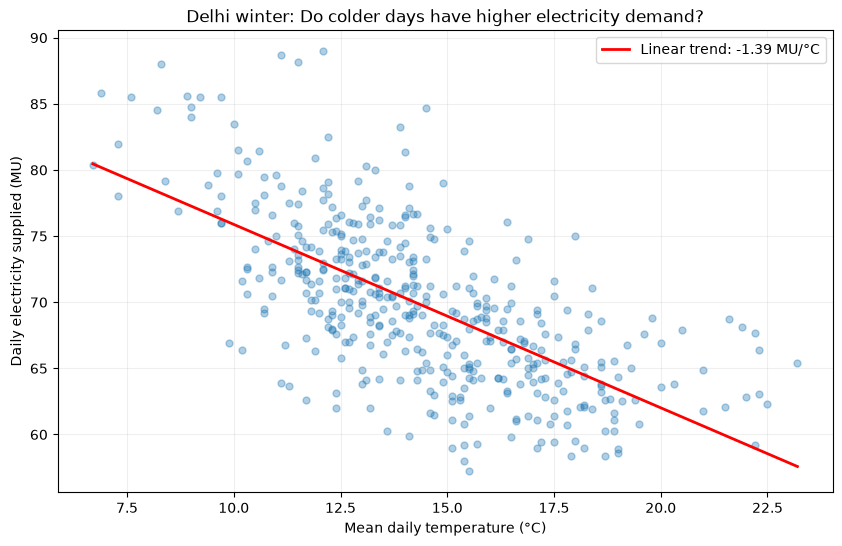

Winter regression slope: -1.387 MU/°C


In [26]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    winter["temperature_2m_mean"],
    winter["energy_met_mu"],
    alpha=0.35,
    s=25
)

x = winter["temperature_2m_mean"].to_numpy()
y = winter["energy_met_mu"].to_numpy()

slope, intercept = np.polyfit(x, y, 1)

xline = np.linspace(x.min(), x.max(), 100)
ax.plot(
    xline,
    slope * xline + intercept,
    color="red",
    linewidth=2,
    label=f"Linear trend: {slope:+.2f} MU/°C"
)

ax.set_xlabel("Mean daily temperature (°C)")
ax.set_ylabel("Daily electricity supplied (MU)")
ax.set_title("Delhi winter: Do colder days have higher electricity demand?")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

print(f"Winter regression slope: {slope:+.3f} MU/°C")

In [27]:
winter_check = winter.copy()

# December belongs to the winter ending the following year
winter_check["winter_year"] = (
    winter_check["date"].dt.year
    + (winter_check["date"].dt.month == 12).astype(int)
)

for col in ["temperature_2m_mean", "energy_met_mu"]:
    winter_check[f"{col}_anomaly"] = (
        winter_check[col]
        - winter_check.groupby("winter_year")[col].transform("mean")
    )

corr = winter_check[
    "temperature_2m_mean_anomaly"
].corr(winter_check["energy_met_mu_anomaly"])

print(f"Within-winter anomaly correlation: {corr:+.3f}")

display(
    winter_check.groupby("winter_year")
    .agg(
        days=("date", "count"),
        mean_temp=("temperature_2m_mean", "mean"),
        mean_demand=("energy_met_mu", "mean"),
    )
    .round(2)
)

Within-winter anomaly correlation: -0.735


,days,mean_temp,mean_demand
winter_year,,,
2019,59,13.98,67.91
2020,88,13.55,70.08
2021,83,15.12,68.04
2022,89,14.03,68.60
2023,90,14.95,72.89
2024,31,15.31,71.33


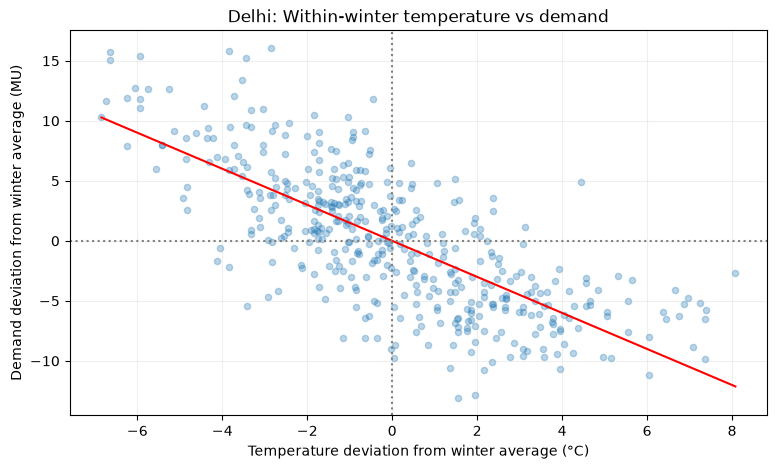

Adjusted slope: -1.502 MU/°C


In [28]:
import matplotlib.pyplot as plt
import numpy as np

x = winter_check["temperature_2m_mean_anomaly"]
y = winter_check["energy_met_mu_anomaly"]

slope, intercept = np.polyfit(x, y, 1)

fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(x, y, alpha=0.3, s=20)

line_x = np.linspace(x.min(), x.max(), 100)
ax.plot(line_x, slope * line_x + intercept, color="red")

ax.axhline(0, color="gray", linestyle=":")
ax.axvline(0, color="gray", linestyle=":")

ax.set_xlabel("Temperature deviation from winter average (°C)")
ax.set_ylabel("Demand deviation from winter average (MU)")
ax.set_title("Delhi: Within-winter temperature vs demand")
ax.grid(alpha=0.2)

plt.show()

print(f"Adjusted slope: {slope:+.3f} MU/°C")

In [29]:
from scipy.stats import linregress

complete_winters = winter_check[
    winter_check["winter_year"].between(2020, 2023)
].copy()

x = complete_winters["temperature_2m_mean_anomaly"]
y = complete_winters["energy_met_mu_anomaly"]

result = linregress(x, y)

print(f"Observations: {len(complete_winters)}")
print(f"Correlation: {result.rvalue:+.3f}")
print(f"Slope: {result.slope:+.3f} MU/°C")
print(f"R²: {result.rvalue**2:.3f}")
print(f"p-value: {result.pvalue:.3g}")

Observations: 350
Correlation: -0.749
Slope: -1.542 MU/°C
R²: 0.561
p-value: 3.06e-64


In [30]:
# Use the full chronological data so differences respect actual dates
daily = analysis.sort_values("date").copy()
daily["winter_year"] = (
    daily["date"].dt.year
    + (daily["date"].dt.month == 12).astype(int)
)

daily["demand_change"] = daily["energy_met_mu"].diff()
daily["temp_change"] = daily["temperature_2m_mean"].diff()

check = daily.loc[
    daily["date"].dt.month.isin([12, 1, 2])
    & daily["winter_year"].between(2020, 2023)
    & daily["date"].sub(daily["date"].shift()).eq(pd.Timedelta(days=1))
    & daily["date"].shift().dt.month.isin([12, 1, 2])
].dropna(subset=["demand_change", "temp_change"])

from scipy.stats import linregress

r = linregress(check["temp_change"], check["demand_change"])

print(f"Days: {len(check)}")
print(f"Daily-change correlation: {r.rvalue:+.3f}")
print(f"Daily-change slope: {r.slope:+.3f} MU/°C")

Days: 338
Daily-change correlation: -0.180
Daily-change slope: -0.610 MU/°C


In [31]:
import pandas as pd
import numpy as np

cold = analysis.sort_values("date").copy()

cold["winter_year"] = (
    cold["date"].dt.year
    + (cold["date"].dt.month == 12).astype(int)
)

winter_mask = (
    cold["date"].dt.month.isin([12, 1, 2])
    & cold["winter_year"].between(2020, 2023)
)

# Rolling values calculated chronologically, including prior days
for window in [1, 3, 5, 7]:
    cold[f"temp_avg_{window}d"] = (
        cold["temperature_2m_mean"]
        .rolling(window, min_periods=window)
        .mean()
    )

winter_cold = cold.loc[winter_mask].copy()

# Remove differences in average demand between winters
winter_cold["demand_anomaly"] = (
    winter_cold["energy_met_mu"]
    - winter_cold.groupby("winter_year")["energy_met_mu"].transform("mean")
)

rows = []

for window in [1, 3, 5, 7]:
    col = f"temp_avg_{window}d"

    temp_anomaly = (
        winter_cold[col]
        - winter_cold.groupby("winter_year")[col].transform("mean")
    )

    valid = pd.DataFrame({
        "temperature": temp_anomaly,
        "demand": winter_cold["demand_anomaly"],
    }).dropna()

    rows.append({
        "Temperature window": f"{window} day(s)",
        "Days": len(valid),
        "Correlation": valid["temperature"].corr(valid["demand"]),
        "R²": valid["temperature"].corr(valid["demand"]) ** 2,
    })

cold_results = pd.DataFrame(rows)

display(cold_results.round(3))

,Temperature window,Days,Correlation,R²
0,1 day(s),350,-0.749,0.561
1,3 day(s),350,-0.786,0.618
2,5 day(s),350,-0.807,0.652
3,7 day(s),350,-0.808,0.653


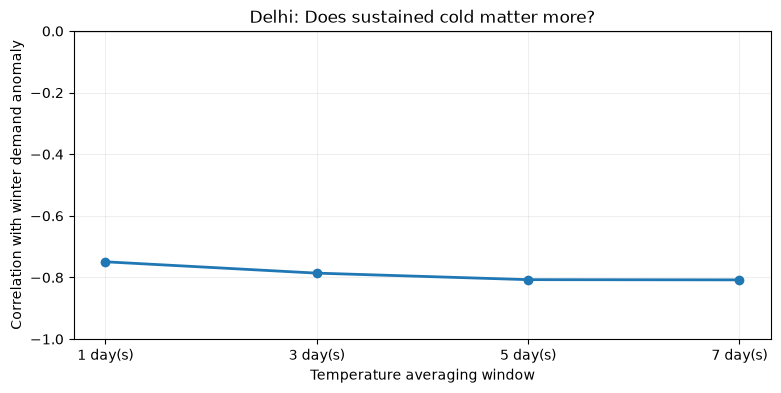

In [32]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(
    cold_results["Temperature window"],
    cold_results["Correlation"],
    marker="o",
    linewidth=2
)

ax.axhline(0, color="gray", linewidth=1)
ax.set_ylim(-1, 0)
ax.set_ylabel("Correlation with winter demand anomaly")
ax.set_xlabel("Temperature averaging window")
ax.set_title("Delhi: Does sustained cold matter more?")
ax.grid(alpha=0.2)

plt.show()

In [33]:
cold = cold.sort_values("date").copy()

# Information available at the end of yesterday
for days in [1, 3, 5, 7]:
    cold[f"past_temp_{days}d"] = (
        cold["temperature_2m_mean"]
        .shift(1)
        .rolling(days, min_periods=days)
        .mean()
    )

# Previous day's electricity demand
cold["previous_demand"] = cold["energy_met_mu"].shift(1)

# Tomorrow-style prediction target: today's demand
cold["target_demand"] = cold["energy_met_mu"]

lagged_winter = cold.loc[
    cold["date"].dt.month.isin([12, 1, 2])
    & cold["winter_year"].between(2020, 2023)
].copy()

# Require a valid previous-day demand reading
lagged_winter = lagged_winter.dropna(
    subset=["target_demand", "previous_demand", "past_temp_7d"]
)

rows = []

for days in [1, 3, 5, 7]:
    rows.append({
        "Temperature history": f"{days} days",
        "Correlation with demand": lagged_winter[
            f"past_temp_{days}d"
        ].corr(lagged_winter["target_demand"]),
    })

display(pd.DataFrame(rows).round(3))

,Temperature history,Correlation with demand
0,1 days,-0.707
1,3 days,-0.728
2,5 days,-0.733
3,7 days,-0.727


In [34]:
print(
    "Previous-day demand correlation:",
    round(
        lagged_winter["previous_demand"].corr(
            lagged_winter["target_demand"]
        ),
        3
    )
)

Previous-day demand correlation: 0.837


In [35]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

features_a = ["previous_demand"]
features_b = ["previous_demand", "past_temp_5d"]

train_part = lagged_winter[
    lagged_winter["winter_year"].between(2020, 2022)
].copy()

test_part = lagged_winter[
    lagged_winter["winter_year"] == 2023
].copy()

models = {}
predictions = {}

for name, features in {
    "Demand only": features_a,
    "Demand + temperature": features_b,
}.items():
    model = Ridge(alpha=1.0)

    model.fit(
        train_part[features],
        train_part["target_demand"]
    )

    predictions[name] = model.predict(test_part[features])
    models[name] = model

print("Training observations:", len(train_part))
print("Test observations:", len(test_part))

Training observations: 252
Test observations: 90


In [36]:
results = []

actual_test = test_part["target_demand"]

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(actual_test, pred),
        "RMSE": root_mean_squared_error(actual_test, pred),
    })

results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df.round(3))

print("\nTemperature model coefficients:")
for feature, coefficient in zip(
    features_b,
    models["Demand + temperature"].coef_
):
    print(f"{feature}: {coefficient:+.3f}")

,Model,MAE,RMSE
0,Demand only,2.581,3.374
1,Demand + temperature,3.414,4.199



Temperature model coefficients:
previous_demand: +0.464
past_temp_5d: -0.932


In [37]:
cold_errors = test_part[[
    "date",
    "temperature_2m_mean",
    "past_temp_5d",
    "target_demand"
]].copy()

cold_errors["demand_only_pred"] = predictions["Demand only"]
cold_errors["weather_pred"] = predictions["Demand + temperature"]

cold_errors["demand_only_error"] = (
    cold_errors["target_demand"] - cold_errors["demand_only_pred"]
).abs()

cold_errors["weather_error"] = (
    cold_errors["target_demand"] - cold_errors["weather_pred"]
).abs()

display(
    cold_errors.nsmallest(15, "temperature_2m_mean")
    .round(2)
)

print("15 coldest days MAE:")
print("Demand only:",
      round(cold_errors.nsmallest(15, "temperature_2m_mean")[
          "demand_only_error"
      ].mean(), 3))

print("With temperature:",
      round(cold_errors.nsmallest(15, "temperature_2m_mean")[
          "weather_error"
      ].mean(), 3))

,date,temperature_2m_mean,past_temp_5d,target_demand,demand_only_pred,weather_pred,demand_only_error,weather_error
1468,2023-01-07,8.2,9.94,84.56,83.91,81.66,0.65,2.90
1467,2023-01-06,8.3,10.78,87.99,82.03,79.77,5.96,8.22
1466,2023-01-05,8.9,11.62,85.60,81.99,78.96,3.61,6.64
1477,2023-01-16,9.0,12.40,83.98,76.75,75.14,7.23,8.84
1478,2023-01-17,9.0,11.78,84.73,80.76,78.08,3.97,6.65
1479,2023-01-18,9.2,10.68,85.51,81.35,79.46,4.16,6.05
1476,2023-01-15,9.4,12.82,78.88,76.53,74.62,2.35,4.26
1465,2023-01-04,9.7,12.66,85.55,78.75,76.08,6.80,9.47
1469,2023-01-08,10.1,9.14,81.50,81.21,80.81,0.29,0.69
1464,2023-01-03,10.6,13.36,81.43,76.17,73.90,5.26,7.53


15 coldest days MAE:
Demand only: 4.355
With temperature: 5.874


## Historical GFS forecasts (Open-Meteo Previous Runs) and a leakage audit

In [39]:
import requests
import pandas as pd

url = "https://previous-runs-api.open-meteo.com/v1/forecast"

params = {
    "latitude": 28.6139,
    "longitude": 77.2090,
    "start_date": "2024-06-01",
    "end_date": "2024-06-07",
    "hourly": ",".join([
        f"temperature_2m_previous_day{i}"
        for i in range(1, 8)
    ]),
    "timezone": "Asia/Kolkata",
}

response = requests.get(url, params=params, timeout=60)

print("HTTP status:", response.status_code)
response.raise_for_status()

forecast_data = pd.DataFrame(response.json()["hourly"])
forecast_data["time"] = pd.to_datetime(forecast_data["time"])

display(forecast_data.head(10))
print("Shape:", forecast_data.shape)
print("\nMissing values:")
print(forecast_data.isna().sum())

HTTP status: 200


,time,temperature_2m_previous_day1,temperature_2m_previous_day2,temperature_2m_previous_day3,temperature_2m_previous_day4,temperature_2m_previous_day5,temperature_2m_previous_day6,temperature_2m_previous_day7
0,2024-06-01 00:00:00,34.1,33.7,34.2,34.8,35.3,36.4,39.8
1,2024-06-01 01:00:00,33.3,32.8,32.7,33.8,34.3,35.0,39.4
2,2024-06-01 02:00:00,32.5,31.7,31.7,33.1,33.4,33.9,39.0
3,2024-06-01 03:00:00,31.7,31.3,31.4,32.4,32.4,33.3,38.6
4,2024-06-01 04:00:00,30.8,30.4,31.0,31.9,31.5,33.2,38.3
5,2024-06-01 05:00:00,29.9,30.2,30.3,29.6,30.9,30.8,39.4
6,2024-06-01 06:00:00,30.4,31.0,30.7,30.7,32.2,31.6,39.6
7,2024-06-01 07:00:00,32.7,33.9,32.0,33.0,34.2,33.1,39.9
8,2024-06-01 08:00:00,36.2,36.3,34.4,35.3,36.3,34.9,40.3
9,2024-06-01 09:00:00,39.1,38.6,37.5,37.6,38.6,37.2,40.7


Shape: (168, 8)

Missing values:
time                            0
temperature_2m_previous_day1    0
temperature_2m_previous_day2    0
temperature_2m_previous_day3    0
temperature_2m_previous_day4    0
temperature_2m_previous_day5    0
temperature_2m_previous_day6    0
temperature_2m_previous_day7    0
dtype: int64


In [40]:
params = {
    "latitude": 28.6139,
    "longitude": 77.2090,
    "start_date": "2024-06-01",
    "end_date": "2024-06-07",
    "hourly": "temperature_2m",
    "timezone": "Asia/Kolkata",
}

r = requests.get(
    "https://archive-api.open-meteo.com/v1/archive",
    params=params,
    timeout=60,
)
r.raise_for_status()

observed = pd.DataFrame(r.json()["hourly"])
observed["time"] = pd.to_datetime(observed["time"])

comparison = forecast_data.merge(
    observed,
    on="time",
    validate="one_to_one",
)

display(comparison.head())

,time,temperature_2m_previous_day1,temperature_2m_previous_day2,temperature_2m_previous_day3,temperature_2m_previous_day4,temperature_2m_previous_day5,temperature_2m_previous_day6,temperature_2m_previous_day7,temperature_2m
0,2024-06-01 00:00:00,34.1,33.7,34.2,34.8,35.3,36.4,39.8,32.4
1,2024-06-01 01:00:00,33.3,32.8,32.7,33.8,34.3,35.0,39.4,32.8
2,2024-06-01 02:00:00,32.5,31.7,31.7,33.1,33.4,33.9,39.0,32.7
3,2024-06-01 03:00:00,31.7,31.3,31.4,32.4,32.4,33.3,38.6,32.2
4,2024-06-01 04:00:00,30.8,30.4,31.0,31.9,31.5,33.2,38.3,32.3


In [41]:
from sklearn.metrics import mean_absolute_error

rows = []

for lead in range(1, 8):
    col = f"temperature_2m_previous_day{lead}"

    valid = comparison[["temperature_2m", col]].dropna()

    rows.append({
        "Lead days": lead,
        "Hours": len(valid),
        "MAE °C": mean_absolute_error(
            valid["temperature_2m"],
            valid[col],
        ),
        "Bias °C": (
            valid[col] - valid["temperature_2m"]
        ).mean(),
    })

forecast_accuracy = pd.DataFrame(rows)
display(forecast_accuracy.round(2))

,Lead days,Hours,MAE °C,Bias °C
0,1,168,1.28,0.60
1,2,168,1.60,1.11
2,3,168,1.60,1.14
3,4,168,1.71,1.07
4,5,168,2.03,1.17
5,6,168,1.97,1.37
6,7,168,4.69,4.46


In [42]:
import requests
import pandas as pd

url = "https://previous-runs-api.open-meteo.com/v1/forecast"

for year in [2021, 2022, 2023, 2024]:
    params = {
        "latitude": 28.6139,
        "longitude": 77.2090,
        "start_date": f"{year}-06-01",
        "end_date": f"{year}-06-03",
        "hourly": (
            "temperature_2m_previous_day1,"
            "temperature_2m_previous_day7"
        ),
        "timezone": "Asia/Kolkata",
    }

    try:
        r = requests.get(url, params=params, timeout=60)
        r.raise_for_status()

        df = pd.DataFrame(r.json()["hourly"])

        print(
            year,
            "rows:", len(df),
            "1-day valid:", df["temperature_2m_previous_day1"].notna().sum(),
            "7-day valid:", df["temperature_2m_previous_day7"].notna().sum(),
        )

    except Exception as e:
        print(year, "ERROR:", str(e)[:200])

2021 rows: 72 1-day valid: 72 7-day valid: 72
2022 rows: 72 1-day valid: 72 7-day valid: 72
2023 rows: 72 1-day valid: 72 7-day valid: 72
2024 rows: 72 1-day valid: 72 7-day valid: 72


In [43]:
import requests
import pandas as pd

url = "https://previous-runs-api.open-meteo.com/v1/forecast"

variables = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
]

rows = []

for year in [2021, 2022, 2023, 2024]:
    params = {
        "latitude": 28.6139,
        "longitude": 77.2090,
        "start_date": f"{year}-06-01",
        "end_date": f"{year}-06-03",
        "hourly": ",".join(
            f"{var}_previous_day{lead}"
            for var in variables
            for lead in [1, 7]
        ),
        "models": "gfs_global",
        "timezone": "Asia/Kolkata",
    }

    response = requests.get(url, params=params, timeout=60)

    if not response.ok:
        print(year, "HTTP", response.status_code, response.text[:200])
        continue

    df = pd.DataFrame(response.json()["hourly"])

    for var in variables:
        for lead in [1, 7]:
            col = f"{var}_previous_day{lead}"

            rows.append({
                "year": year,
                "variable": var,
                "lead_days": lead,
                "valid_hours": df[col].notna().sum(),
                "total_hours": len(df),
            })

coverage = pd.DataFrame(rows)
display(coverage)

,year,variable,lead_days,valid_hours,total_hours
0,2021,temperature_2m,1,72,72
1,2021,temperature_2m,7,72,72
2,2021,relative_humidity_2m,1,0,72
3,2021,relative_humidity_2m,7,0,72
4,2021,precipitation,1,0,72
5,2021,precipitation,7,0,72
6,2022,temperature_2m,1,72,72
7,2022,temperature_2m,7,72,72
8,2022,relative_humidity_2m,1,0,72
9,2022,relative_humidity_2m,7,0,72


In [44]:
import requests
import pandas as pd

url = "https://previous-runs-api.open-meteo.com/v1/forecast"

periods = [
    ("2021-01-01", "2021-01-07"),
    ("2021-03-01", "2021-03-07"),
    ("2021-04-01", "2021-04-07"),
]

for start, end in periods:
    params = {
        "latitude": 28.6139,
        "longitude": 77.2090,
        "start_date": start,
        "end_date": end,
        "hourly": ",".join([
            "temperature_2m_previous_day1",
            "temperature_2m_previous_day7",
        ]),
        "models": "gfs_global",
        "timezone": "Asia/Kolkata",
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    df = pd.DataFrame(response.json()["hourly"])

    print(
        start,
        "1-day:", df["temperature_2m_previous_day1"].notna().sum(),
        "7-day:", df["temperature_2m_previous_day7"].notna().sum(),
        "of", len(df), "hours"
    )

2021-01-01 1-day: 0 7-day: 0 of 168 hours
2021-03-01 1-day: 0 7-day: 0 of 168 hours
2021-04-01 1-day: 168 7-day: 168 of 168 hours


In [45]:
origin = pd.Timestamp("2024-05-31")

rows = []

for h in range(1, 8):
    target_date = origin + pd.Timedelta(days=h)

    col = f"temperature_2m_previous_day{h}"

    day = forecast_data.loc[
        forecast_data["time"].dt.normalize() == target_date,
        col
    ]

    rows.append({
        "origin": origin,
        "target_date": target_date,
        "horizon": h,
        "forecast_mean_temp": day.mean(),
        "forecast_max_temp": day.max(),
        "forecast_min_temp": day.min(),
        "valid_hours": day.notna().sum(),
    })

weather_7d = pd.DataFrame(rows)

display(weather_7d.round(2))

assert (weather_7d["valid_hours"] == 24).all()

,origin,target_date,horizon,forecast_mean_temp,forecast_max_temp,forecast_min_temp,valid_hours
0,2024-05-31,2024-06-01,1,37.26,44.4,29.9,24
1,2024-05-31,2024-06-02,2,37.66,44.3,30.6,24
2,2024-05-31,2024-06-03,3,38.29,45.7,30.1,24
3,2024-05-31,2024-06-04,4,38.43,45.1,31.0,24
4,2024-05-31,2024-06-05,5,38.79,45.0,32.9,24
5,2024-05-31,2024-06-06,6,38.57,45.7,32.2,24
6,2024-05-31,2024-06-07,7,41.98,46.7,37.3,24


In [46]:
actual_daily = (
    comparison
    .assign(date=comparison["time"].dt.normalize())
    .groupby("date")["temperature_2m"]
    .agg(["mean", "max", "min"])
    .reset_index()
)

actual_daily.columns = [
    "target_date",
    "actual_mean_temp",
    "actual_max_temp",
    "actual_min_temp",
]

weather_7d = weather_7d.merge(
    actual_daily,
    on="target_date",
    validate="one_to_one",
)

weather_7d["mean_temp_error"] = (
    weather_7d["forecast_mean_temp"]
    - weather_7d["actual_mean_temp"]
)

display(weather_7d.round(2))

,origin,target_date,horizon,forecast_mean_temp,forecast_max_temp,forecast_min_temp,valid_hours,actual_mean_temp,actual_max_temp,actual_min_temp,mean_temp_error
0,2024-05-31,2024-06-01,1,37.26,44.4,29.9,24,37.43,44.0,31.3,-0.17
1,2024-05-31,2024-06-02,2,37.66,44.3,30.6,24,36.38,41.4,30.5,1.28
2,2024-05-31,2024-06-03,3,38.29,45.7,30.1,24,36.90,44.4,29.6,1.38
3,2024-05-31,2024-06-04,4,38.43,45.1,31.0,24,36.90,43.1,30.9,1.53
4,2024-05-31,2024-06-05,5,38.79,45.0,32.9,24,36.66,41.7,30.2,2.12
5,2024-05-31,2024-06-06,6,38.57,45.7,32.2,24,35.01,40.8,28.2,3.56
6,2024-05-31,2024-06-07,7,41.98,46.7,37.3,24,35.20,42.2,28.9,6.78


In [47]:
weather_7d["absolute_error"] = weather_7d["mean_temp_error"].abs()

print("7-day mean absolute error:",
      round(weather_7d["absolute_error"].mean(), 2), "°C")

print("First 3 days MAE:",
      round(weather_7d.iloc[:3]["absolute_error"].mean(), 2), "°C")

print("Last 4 days MAE:",
      round(weather_7d.iloc[3:]["absolute_error"].mean(), 2), "°C")

7-day mean absolute error: 2.4 °C
First 3 days MAE: 0.94 °C
Last 4 days MAE: 3.5 °C


In [48]:
print("Weather response metadata:")
for key, value in response.json().items():
    if key not in ("hourly", "daily"):
        print(key, ":", value)

print("\nWeather forecast dataframe:")
print(forecast_data.columns.tolist())

Weather response metadata:
latitude : 28.64302
longitude : 77.22656
generationtime_ms : 82.77499675750732
utc_offset_seconds : 19800
timezone : Asia/Kolkata
timezone_abbreviation : GMT+5:30
elevation : 214.0
hourly_units : {'time': 'iso8601', 'temperature_2m_previous_day1': '°C', 'temperature_2m_previous_day7': '°C'}

Weather forecast dataframe:
['time', 'temperature_2m_previous_day1', 'temperature_2m_previous_day2', 'temperature_2m_previous_day3', 'temperature_2m_previous_day4', 'temperature_2m_previous_day5', 'temperature_2m_previous_day6', 'temperature_2m_previous_day7']


In [49]:
import requests
import pandas as pd

gfs_params = {
    "latitude": 28.6139,
    "longitude": 77.2090,
    "start_date": "2024-06-01",
    "end_date": "2024-06-07",
    "hourly": ",".join(
        f"temperature_2m_previous_day{i}"
        for i in range(1, 8)
    ),
    "models": "gfs_global",
    "timezone": "Asia/Kolkata",
}

gfs_response = requests.get(
    "https://previous-runs-api.open-meteo.com/v1/forecast",
    params=gfs_params,
    timeout=60,
)
gfs_response.raise_for_status()

gfs_json = gfs_response.json()
gfs_sample = pd.DataFrame(gfs_json["hourly"])
gfs_sample["time"] = pd.to_datetime(gfs_sample["time"])

print("Requested model:", gfs_params["models"])
print("Returned grid:", gfs_json["latitude"], gfs_json["longitude"])
print("Rows:", len(gfs_sample))
print("Missing values:")
print(gfs_sample.isna().sum())

Requested model: gfs_global
Returned grid: 28.64302 77.22656
Rows: 168
Missing values:
time                            0
temperature_2m_previous_day1    0
temperature_2m_previous_day2    0
temperature_2m_previous_day3    0
temperature_2m_previous_day4    0
temperature_2m_previous_day5    0
temperature_2m_previous_day6    0
temperature_2m_previous_day7    0
dtype: int64


In [50]:
from pathlib import Path
import json

sample_path = Path("../data/processed/gridpulse_gfs_sample_2024.parquet")
metadata_path = sample_path.with_suffix(".json")

gfs_sample.to_parquet(sample_path, index=False)

metadata = {
    "endpoint": gfs_response.url,
    "requested_model": "gfs_global",
    "requested_coordinates": [28.6139, 77.2090],
    "returned_coordinates": [
        gfs_json["latitude"],
        gfs_json["longitude"]
    ],
    "timezone": gfs_json["timezone"],
    "forecast_type": "fixed_lead_previous_runs",
    "note": "Not guaranteed to represent one forecast initialization",
}

metadata_path.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

print("Saved:", sample_path)
print("Saved:", metadata_path)

Saved: ..\data\processed\gridpulse_gfs_sample_2024.parquet
Saved: ..\data\processed\gridpulse_gfs_sample_2024.json


In [51]:
origin = pd.Timestamp("2024-05-31 18:00")

audit = []

for h in range(1, 8):
    target_day = origin.normalize() + pd.Timedelta(days=h)
    col = f"temperature_2m_previous_day{h}"

    day = gfs_sample.loc[
        gfs_sample["time"].dt.normalize().eq(target_day)
    ].copy()

    nominal_issue = day["time"] - pd.Timedelta(days=h)

    audit.append({
        "horizon": h,
        "target_date": target_day.date(),
        "valid_hours": day[col].notna().sum(),
        "nominally_after_cutoff": (
            (nominal_issue > origin) & day[col].notna()
        ).sum(),
    })

audit_df = pd.DataFrame(audit)
display(audit_df)

print(
    "Total hours nominally after cutoff:",
    audit_df["nominally_after_cutoff"].sum()
)

,horizon,target_date,valid_hours,nominally_after_cutoff
0,1,2024-06-01,24,5
1,2,2024-06-02,24,5
2,3,2024-06-03,24,5
3,4,2024-06-04,24,5
4,5,2024-06-05,24,5
5,6,2024-06-06,24,5
6,7,2024-06-07,24,5


Total hours nominally after cutoff: 35


In [52]:
cutoff = pd.Timestamp("2024-05-31 18:00")

rows = []

for h in range(1, 8):
    target_date = cutoff.normalize() + pd.Timedelta(days=h)

    for hour in range(24):
        valid_time = target_date + pd.Timedelta(hours=hour)

        # Choose a lead whose nominal forecast time is not after cutoff.
        eligible_leads = [
            lead for lead in range(1, 8)
            if valid_time - pd.Timedelta(days=lead) <= cutoff
        ]

        rows.append({
            "target_date": target_date,
            "hour": hour,
            "selected_lead": min(eligible_leads) if eligible_leads else None,
        })

availability = pd.DataFrame(rows)

display(
    availability.pivot_table(
        index="hour",
        columns="target_date",
        values="selected_lead",
        aggfunc="first"
    )
)

target_date,2024-06-01,2024-06-02,2024-06-03,2024-06-04,2024-06-05,2024-06-06,2024-06-07
hour,,,,,,,
0,1.0,2.0,3.0,4.0,5.0,6.0,7.0
1,1.0,2.0,3.0,4.0,5.0,6.0,7.0
2,1.0,2.0,3.0,4.0,5.0,6.0,7.0
3,1.0,2.0,3.0,4.0,5.0,6.0,7.0
4,1.0,2.0,3.0,4.0,5.0,6.0,7.0
5,1.0,2.0,3.0,4.0,5.0,6.0,7.0
6,1.0,2.0,3.0,4.0,5.0,6.0,7.0
7,1.0,2.0,3.0,4.0,5.0,6.0,7.0
8,1.0,2.0,3.0,4.0,5.0,6.0,7.0


In [53]:
import requests
import pandas as pd
from pathlib import Path

url = "https://previous-runs-api.open-meteo.com/v1/forecast"

start_dates = pd.date_range(
    "2021-04-01", "2024-12-01", freq="MS"
)

frames = []

for start in start_dates:
    end = min(
        start + pd.offsets.MonthEnd(0),
        pd.Timestamp("2024-12-31")
    )

    params = {
        "latitude": 28.6139,
        "longitude": 77.2090,
        "start_date": start.strftime("%Y-%m-%d"),
        "end_date": end.strftime("%Y-%m-%d"),
        "hourly": ",".join(
            f"temperature_2m_previous_day{i}"
            for i in range(1, 8)
        ),
        "models": "gfs_global",
        "timezone": "Asia/Kolkata",
    }

    response = requests.get(url, params=params, timeout=90)
    response.raise_for_status()

    df = pd.DataFrame(response.json()["hourly"])
    df["time"] = pd.to_datetime(df["time"])

    frames.append(df)

    print(
        start.strftime("%Y-%m"),
        "rows:", len(df)
    )

gfs_history = (
    pd.concat(frames, ignore_index=True)
    .sort_values("time")
    .reset_index(drop=True)
)

print("\nTotal rows:", len(gfs_history))
print("Range:", gfs_history["time"].min(),
      "to", gfs_history["time"].max())

2021-04 rows: 720
2021-05 rows: 744
2021-06 rows: 720
2021-07 rows: 744
2021-08 rows: 744
2021-09 rows: 720
2021-10 rows: 744
2021-11 rows: 720
2021-12 rows: 744
2022-01 rows: 744
2022-02 rows: 672
2022-03 rows: 744
2022-04 rows: 720
2022-05 rows: 744
2022-06 rows: 720
2022-07 rows: 744
2022-08 rows: 744
2022-09 rows: 720
2022-10 rows: 744
2022-11 rows: 720
2022-12 rows: 744
2023-01 rows: 744
2023-02 rows: 672
2023-03 rows: 744
2023-04 rows: 720
2023-05 rows: 744
2023-06 rows: 720
2023-07 rows: 744
2023-08 rows: 744
2023-09 rows: 720
2023-10 rows: 744
2023-11 rows: 720
2023-12 rows: 744
2024-01 rows: 744
2024-02 rows: 696
2024-03 rows: 744
2024-04 rows: 720
2024-05 rows: 744
2024-06 rows: 720
2024-07 rows: 744
2024-08 rows: 744
2024-09 rows: 720
2024-10 rows: 744
2024-11 rows: 720
2024-12 rows: 744

Total rows: 32904
Range: 2021-04-01 00:00:00 to 2024-12-31 23:00:00


In [54]:
lead_cols = [
    f"temperature_2m_previous_day{i}"
    for i in range(1, 8)
]

coverage = (
    gfs_history
    .assign(year=gfs_history["time"].dt.year)
    .groupby("year")[lead_cols]
    .agg(lambda x: round(100 * x.notna().mean(), 1))
)

print("Forecast coverage (%):")
display(coverage)

assert not gfs_history["time"].duplicated().any()

path = Path("../data/processed/gridpulse_gfs_previous_runs_2021_2024.parquet")

gfs_history.to_parquet(path, index=False)

print("Saved:", path)
print("Size:", round(path.stat().st_size / 1024**2, 2), "MB")

Forecast coverage (%):


,temperature_2m_previous_day1,temperature_2m_previous_day2,temperature_2m_previous_day3,temperature_2m_previous_day4,temperature_2m_previous_day5,temperature_2m_previous_day6,temperature_2m_previous_day7
year,,,,,,,
2021,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2022,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2023,99.5,99.5,99.5,99.5,99.5,99.5,99.5
2024,94.9,94.6,94.3,94.1,93.8,93.5,93.2


Saved: ..\data\processed\gridpulse_gfs_previous_runs_2021_2024.parquet
Size: 0.54 MB


In [55]:
lead_cols = [
    f"temperature_2m_previous_day{i}"
    for i in range(1, 8)
]

monthly_coverage = (
    gfs_history
    .assign(month=gfs_history["time"].dt.to_period("M"))
    .groupby("month")[lead_cols]
    .agg(lambda s: 100 * s.notna().mean())
)

display(monthly_coverage.loc["2024"].round(1))

,temperature_2m_previous_day1,temperature_2m_previous_day2,temperature_2m_previous_day3,temperature_2m_previous_day4,temperature_2m_previous_day5,temperature_2m_previous_day6,temperature_2m_previous_day7
month,,,,,,,
2024-01,39.7,36.4,33.2,30.0,26.7,23.5,20.3
2024-02,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2024-03,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2024-04,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2024-05,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2024-06,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2024-07,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2024-08,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2024-09,100.0,100.0,100.0,100.0,100.0,100.0,100.0


In [56]:
daily_coverage = (
    gfs_history
    .assign(date=gfs_history["time"].dt.normalize())
    .groupby("date")[lead_cols]
    .agg(lambda s: s.notna().sum())
)

complete_days = daily_coverage.eq(24)

print("Days with 24 forecast hours, by lead:")
print(complete_days.sum())

print("\nDays with all seven leads complete:")
print(complete_days.all(axis=1).sum())

print("\n2024 incomplete days by month:")
incomplete_2024 = complete_days.loc["2024"].all(axis=1)

display(
    incomplete_2024
    .groupby(incomplete_2024.index.to_period("M"))
    .agg(["sum", "count"])
    .rename(columns={"sum": "complete_days", "count": "total_days"})
)

Days with 24 forecast hours, by lead:
temperature_2m_previous_day1    1350
temperature_2m_previous_day2    1349
temperature_2m_previous_day3    1348
temperature_2m_previous_day4    1347
temperature_2m_previous_day5    1346
temperature_2m_previous_day6    1345
temperature_2m_previous_day7    1344
dtype: int64

Days with all seven leads complete:
1344

2024 incomplete days by month:


,complete_days,total_days
date,,
2024-01,6,31
2024-02,29,29
2024-03,31,31
2024-04,30,30
2024-05,31,31
2024-06,30,30
2024-07,31,31
2024-08,31,31
2024-09,30,30


In [57]:
origin = pd.Timestamp("2024-05-31 18:00")

rows = []

for h in range(1, 8):
    target_date = origin.normalize() + pd.Timedelta(days=h)

    # Additional 24-hour safety margin
    required_lead = h + 1

    rows.append({
        "horizon": h,
        "target_date": target_date,
        "required_lead": required_lead,
        "available": required_lead <= 7,
    })

safety_audit = pd.DataFrame(rows)
display(safety_audit)

,horizon,target_date,required_lead,available
0,1,2024-06-01,2,True
1,2,2024-06-02,3,True
2,3,2024-06-03,4,True
3,4,2024-06-04,5,True
4,5,2024-06-05,6,True
5,6,2024-06-06,7,True
6,7,2024-06-07,8,False


In [58]:
origin = pd.Timestamp("2024-05-31 23:59")

rows = []

for h in range(1, 8):
    target_date = origin.normalize() + pd.Timedelta(days=h)

    day = gfs_sample.loc[
        gfs_sample["time"].dt.normalize() == target_date
    ]

    col = f"temperature_2m_previous_day{h}"
    nominal_issue = day["time"] - pd.Timedelta(days=h)

    rows.append({
        "horizon": h,
        "valid_hours": day[col].notna().sum(),
        "nominally_after_cutoff": (
            (nominal_issue > origin) & day[col].notna()
        ).sum(),
    })

timing_check = pd.DataFrame(rows)
display(timing_check)

,horizon,valid_hours,nominally_after_cutoff
0,1,24,0
1,2,24,0
2,3,24,0
3,4,24,0
4,5,24,0
5,6,24,0
6,7,24,0


In [59]:
lead_cols = [
    f"temperature_2m_previous_day{i}"
    for i in range(1, 8)
]

daily_gfs = (
    gfs_history
    .assign(date=gfs_history["time"].dt.normalize())
    .groupby("date")[lead_cols]
    .agg(["mean", "max", "min", "count"])
)

daily_gfs.columns = [
    f"{lead}_{stat}"
    for lead, stat in daily_gfs.columns
]

daily_gfs = daily_gfs.reset_index()

# Don't treat partial days as complete daily forecasts.
for lead in lead_cols:
    incomplete = daily_gfs[f"{lead}_count"] != 24

    for stat in ["mean", "max", "min"]:
        daily_gfs.loc[incomplete, f"{lead}_{stat}"] = float("nan")

print("Daily records:", len(daily_gfs))
display(daily_gfs.head(3))

Daily records: 1371


,date,temperature_2m_previous_day1_mean,temperature_2m_previous_day1_max,temperature_2m_previous_day1_min,temperature_2m_previous_day1_count,temperature_2m_previous_day2_mean,temperature_2m_previous_day2_max,temperature_2m_previous_day2_min,temperature_2m_previous_day2_count,temperature_2m_previous_day3_mean,...,temperature_2m_previous_day5_min,temperature_2m_previous_day5_count,temperature_2m_previous_day6_mean,temperature_2m_previous_day6_max,temperature_2m_previous_day6_min,temperature_2m_previous_day6_count,temperature_2m_previous_day7_mean,temperature_2m_previous_day7_max,temperature_2m_previous_day7_min,temperature_2m_previous_day7_count
0,2021-04-01,29.841667,36.0,23.5,24,30.191667,36.5,24.1,24,29.933333,...,23.9,24,29.837500,36.5,23.5,24,29.570833,35.2,24.2,24
1,2021-04-02,29.812500,36.2,23.8,24,29.891667,36.3,23.9,24,29.520833,...,24.6,24,30.820833,37.5,24.5,24,30.954167,37.6,23.7,24
2,2021-04-03,30.341667,36.9,23.5,24,30.758333,37.0,23.7,24,30.841667,...,24.6,24,31.208333,37.6,24.8,24,32.037500,38.8,25.4,24


In [60]:
records = []

for origin in pd.date_range("2021-04-01", "2024-12-24"):
    for h in range(1, 8):
        target_date = origin + pd.Timedelta(days=h)

        match = daily_gfs.loc[daily_gfs["date"] == target_date]

        if match.empty:
            continue

        row = match.iloc[0]
        lead = f"temperature_2m_previous_day{h}"

        records.append({
            "origin": origin,
            "target_date": target_date,
            "horizon": h,
            "forecast_temp_mean": row[f"{lead}_mean"],
            "forecast_temp_max": row[f"{lead}_max"],
            "forecast_temp_min": row[f"{lead}_min"],
        })

weather_features = pd.DataFrame(records)

print("Origin-target pairs:", len(weather_features))
print("Missing forecast means:",
      weather_features["forecast_temp_mean"].isna().sum())

display(weather_features.head(10))

Origin-target pairs: 9548
Missing forecast means: 168


,origin,target_date,horizon,forecast_temp_mean,forecast_temp_max,forecast_temp_min
0,2021-04-01,2021-04-02,1,29.812500,36.2,23.8
1,2021-04-01,2021-04-03,2,30.758333,37.0,23.7
2,2021-04-01,2021-04-04,3,32.220833,38.8,25.6
3,2021-04-01,2021-04-05,4,35.075000,42.2,27.9
4,2021-04-01,2021-04-06,5,35.712500,42.0,30.7
5,2021-04-01,2021-04-07,6,34.104167,39.5,29.5
6,2021-04-01,2021-04-08,7,30.979167,36.3,26.0
7,2021-04-02,2021-04-03,1,30.341667,36.9,23.5
8,2021-04-02,2021-04-04,2,32.050000,38.4,25.6
9,2021-04-02,2021-04-05,3,34.775000,41.7,27.6


In [61]:
window_coverage = (
    weather_features
    .assign(
        year=weather_features["origin"].dt.year,
        available=weather_features["forecast_temp_mean"].notna()
    )
    .groupby(["origin", "year"])
    .agg(
        horizons=("horizon", "nunique"),
        available_days=("available", "sum")
    )
    .reset_index()
)

window_coverage["complete"] = (
    (window_coverage["horizons"] == 7)
    & (window_coverage["available_days"] == 7)
)

display(
    window_coverage.groupby("year").agg(
        total_windows=("origin", "size"),
        complete_windows=("complete", "sum")
    )
)

print("\nIncomplete 2024 origins:")
display(
    window_coverage.loc[
        (window_coverage["year"] == 2024)
        & ~window_coverage["complete"]
    ].head(30)
)

,total_windows,complete_windows
year,,
2021,275,275
2022,365,365
2023,365,356
2024,359,341



Incomplete 2024 origins:


,origin,year,horizons,available_days,complete
1005,2024-01-01,2024,7,0,False
1006,2024-01-02,2024,7,0,False
1007,2024-01-03,2024,7,0,False
1008,2024-01-04,2024,7,0,False
1009,2024-01-05,2024,7,0,False
1010,2024-01-06,2024,7,0,False
1011,2024-01-07,2024,7,0,False
1012,2024-01-08,2024,7,0,False
1013,2024-01-09,2024,7,0,False
1014,2024-01-10,2024,7,0,False


## Align GFS forecasts with the 2024 validation benchmark

In [62]:
demand = pd.read_csv(
    "../data/processed/gridpulse_v2_development.csv",
    parse_dates=["date"]
)

demand = demand[["date", "energy_met_mu"]].copy()

weather_demand = weather_features.merge(
    demand.rename(columns={
        "date": "target_date",
        "energy_met_mu": "actual_energy_mu"
    }),
    on="target_date",
    how="left",
    validate="many_to_one"
)

weather_demand["split"] = (
    weather_demand["target_date"]
    .lt(pd.Timestamp("2024-01-01"))
    .map({True: "train", False: "validation"})
)

display(
    weather_demand.groupby("split").agg(
        records=("target_date", "size"),
        missing_weather=("forecast_temp_mean",
                         lambda s: s.isna().sum()),
        missing_demand=("actual_energy_mu",
                        lambda s: s.isna().sum())
    )
)

,records,missing_weather,missing_demand
split,,,
train,7007,14,77
validation,2541,154,0


In [64]:
from pathlib import Path
import pandas as pd

benchmark_path = Path(
    "../data/processed/gridpulse_chronos2_validation_2024.parquet"
)

benchmark = pd.read_parquet(benchmark_path)

print("Shape:", benchmark.shape)
print("Columns:", benchmark.columns.tolist())
display(benchmark.head(3))

Shape: (2520, 7)
Columns: ['origin', 'target_date', 'horizon', 'actual_mu', 'chronos2_zero_shot_weather', 'chronos2_lora_weather_200', 'chronos2_lora_calendar_200']


,origin,target_date,horizon,actual_mu,chronos2_zero_shot_weather,chronos2_lora_weather_200,chronos2_lora_calendar_200
0,2023-12-31,2024-01-01,1,79.620003,74.600479,74.654045,74.916092
1,2023-12-31,2024-01-02,2,80.110001,75.545013,75.609734,76.080086
2,2023-12-31,2024-01-03,3,84.930000,76.305725,76.374435,76.839890


In [65]:
benchmark["origin"] = pd.to_datetime(benchmark["origin"])
benchmark["target_date"] = pd.to_datetime(benchmark["target_date"])

matched = benchmark.merge(
    weather_features[
        [
            "origin", "target_date", "horizon",
            "forecast_temp_mean",
            "forecast_temp_max",
            "forecast_temp_min"
        ]
    ],
    on=["origin", "target_date", "horizon"],
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Benchmark rows:", len(benchmark))
print("Matched rows:", len(matched))
print("\nJoin status:")
print(matched["_merge"].value_counts())

print("\nMissing forecast temperatures:",
      matched["forecast_temp_mean"].isna().sum())

Benchmark rows: 2520
Matched rows: 2520

Join status:
_merge
both          2520
left_only        0
right_only       0
Name: count, dtype: int64

Missing forecast temperatures: 133


In [66]:
origin_coverage = (
    matched.groupby("origin")
    .agg(
        targets=("horizon", "nunique"),
        weather_days=("forecast_temp_mean", "count")
    )
)

origin_coverage["complete"] = (
    (origin_coverage["targets"] == 7)
    & (origin_coverage["weather_days"] == 7)
)

print("Total origins:", len(origin_coverage))
print("Complete weather origins:",
      origin_coverage["complete"].sum())

print("\nIncomplete origins by month:")
incomplete = origin_coverage.loc[~origin_coverage["complete"]]

display(
    incomplete.groupby(incomplete.index.to_period("M"))
    .size()
)

Total origins: 360
Complete weather origins: 341

Incomplete origins by month:


origin
2023-12     1
2024-01    18
Freq: M, dtype: int64

In [67]:
matched["weather_complete"] = matched["origin"].map(
    origin_coverage["complete"]
)

models = [
    "chronos2_zero_shot_weather",
    "chronos2_lora_weather_200",
    "chronos2_lora_calendar_200",
]

rows = []

for subset, df in matched.groupby("weather_complete"):
    for model in models:
        rows.append({
            "weather_complete": subset,
            "model": model,
            "origins": df["origin"].nunique(),
            "MAE": (df["actual_mu"] - df[model]).abs().mean(),
        })

difficulty = pd.DataFrame(rows)

display(
    difficulty.pivot(
        index="model",
        columns="weather_complete",
        values="MAE"
    ).round(3)
)

weather_complete,False,True
model,,
chronos2_lora_calendar_200,2.992,7.085
chronos2_lora_weather_200,2.998,7.101
chronos2_zero_shot_weather,3.009,7.146


In [68]:
demand_series = (
    pd.read_csv(
        "../data/processed/gridpulse_v2_development.csv",
        parse_dates=["date"]
    )
    .set_index("date")["energy_met_mu"]
    .sort_index()
)

weather_ok = (
    weather_features
    .groupby("origin")["forecast_temp_mean"]
    .agg(["count", "size"])
)

weather_ok["complete"] = (
    (weather_ok["count"] == 7)
    & (weather_ok["size"] == 7)
)

eligible = []

for origin in weather_ok.index:
    if origin + pd.Timedelta(days=7) >= pd.Timestamp("2024-01-01"):
        continue

    history_dates = pd.date_range(
        end=origin, periods=56, freq="D"
    )

    target_dates = pd.date_range(
        start=origin + pd.Timedelta(days=1),
        periods=7, freq="D"
    )

    history = demand_series.reindex(history_dates)
    targets = demand_series.reindex(target_dates)

    eligible.append({
        "origin": origin,
        "weather_complete": weather_ok.loc[origin, "complete"],
        "demand_complete": (
            history.notna().all()
            and targets.notna().all()
        ),
    })

eligibility = pd.DataFrame(eligible)

print("Total candidate origins:", len(eligibility))
print(
    "Complete demand + weather:",
    (
        eligibility["weather_complete"]
        & eligibility["demand_complete"]
    ).sum()
)

display(
    eligibility.groupby(
        ["weather_complete", "demand_complete"]
    ).size()
)

Total candidate origins: 998
Complete demand + weather: 638


weather_complete  demand_complete
False             True                 2
True              False              358
                  True               638
dtype: int64

In [69]:
valid_origins = eligibility.loc[
    eligibility["weather_complete"] &
    eligibility["demand_complete"],
    "origin"
]

season_counts = (
    valid_origins
    .dt.month
    .value_counts()
    .sort_index()
    .rename_axis("month")
    .reset_index(name="training_windows")
)

season_counts["month_name"] = pd.to_datetime(
    season_counts["month"], format="%m"
).dt.strftime("%b")

display(season_counts[["month_name", "training_windows"]])

print(
    "Training range:",
    valid_origins.min().date(),
    "to",
    valid_origins.max().date()
)

,month_name,training_windows
0,Jan,31
1,Feb,51
2,Mar,38
3,Apr,37
4,May,83
5,Jun,90
6,Jul,52
7,Aug,31
8,Sep,50
9,Oct,62


Training range: 2021-04-24 to 2023-12-22


In [70]:
origin = valid_origins.iloc[0]

past_dates = pd.date_range(end=origin, periods=56, freq="D")
future_dates = pd.date_range(
    start=origin + pd.Timedelta(days=1),
    periods=7,
    freq="D"
)

past_demand = demand_series.reindex(past_dates)

future_weather = (
    weather_features.loc[
        weather_features["origin"].eq(origin)
    ]
    .sort_values("horizon")
)

assert len(past_demand) == 56
assert past_demand.notna().all()
assert len(future_weather) == 7
assert future_weather[
    ["forecast_temp_mean", "forecast_temp_max", "forecast_temp_min"]
].notna().all().all()

print("Origin:", origin.date())
print("History:", past_dates[0].date(), "→", past_dates[-1].date())
print("Prediction:", future_dates[0].date(), "→", future_dates[-1].date())

display(
    future_weather[
        [
            "target_date",
            "horizon",
            "forecast_temp_mean",
            "forecast_temp_max",
            "forecast_temp_min"
        ]
    ]
)

Origin: 2021-04-24
History: 2021-02-28 → 2021-04-24
Prediction: 2021-04-25 → 2021-05-01


,target_date,horizon,forecast_temp_mean,forecast_temp_max,forecast_temp_min
161,2021-04-25,1,32.854167,38.6,26.7
162,2021-04-26,2,35.116667,40.8,28.8
163,2021-04-27,3,37.337500,42.9,31.6
164,2021-04-28,4,38.570833,43.9,33.0
165,2021-04-29,5,38.879167,44.0,33.4
166,2021-04-30,6,38.716667,43.7,34.1
167,2021-05-01,7,37.583333,42.1,32.9


In [71]:
print("Shape:", train_weather.shape)
print("Columns:", train_weather.columns.tolist())

display(train_weather.head(3))

print("\nDate range:")
if "date" in train_weather.columns:
    print(train_weather["date"].min(), "→", train_weather["date"].max())
else:
    print("Index:", train_weather.index.min(), "→", train_weather.index.max())

Shape: (1827, 14)
Columns: ['date', 'energy_met_mu', 'max_demand_met_mw', 'energy_missing', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'relative_humidity_2m_mean', 'apparent_temperature_max', 'precipitation_sum', 'year_sin', 'year_cos', 'week_sin', 'week_cos']


,date,energy_met_mu,max_demand_met_mw,energy_missing,temperature_2m_max,temperature_2m_min,temperature_2m_mean,relative_humidity_2m_mean,apparent_temperature_max,precipitation_sum,year_sin,year_cos,week_sin,week_cos
0,2018-12-31,69.0,4292.0,False,20.7,5.3,12.3,70,17.9,0.0,-0.004301,0.999991,0.000000,1.000000
1,2019-01-01,69.6,4336.0,False,20.2,5.8,12.7,71,18.7,0.0,0.017202,0.999852,0.781831,0.623490
2,2019-01-02,69.0,4183.0,False,21.1,7.5,14.1,71,19.8,0.0,0.034398,0.999408,0.974928,-0.222521



Date range:
2018-12-31 00:00:00 → 2023-12-31 00:00:00


In [72]:
import numpy as np
import pandas as pd

origin = valid_origins.iloc[0]

past_dates = pd.date_range(end=origin, periods=56)
future_dates = pd.date_range(
    start=origin + pd.Timedelta(days=1),
    periods=7
)

# Historical observations and known calendar values
history = (
    train_weather.set_index("date")
    .reindex(past_dates)
)

future_calendar = (
    train_weather.set_index("date")
    .reindex(future_dates)
)

# Archived future weather forecasts
forecast = (
    weather_features.loc[
        weather_features["origin"].eq(origin)
    ]
    .set_index("target_date")
    .reindex(future_dates)
)

# Combine observed past temperatures with forecast future temperatures
temperature_channels = {
    "temperature_mean": (
        "temperature_2m_mean", "forecast_temp_mean"
    ),
    "temperature_max": (
        "temperature_2m_max", "forecast_temp_max"
    ),
    "temperature_min": (
        "temperature_2m_min", "forecast_temp_min"
    ),
}

example = {
    "origin": origin,
    "target": history["energy_met_mu"].to_numpy(dtype="float32"),
    "future_target": future_calendar["energy_met_mu"].to_numpy(dtype="float32"),
    "covariates": {},
}

for name, (past_col, future_col) in temperature_channels.items():
    example["covariates"][name] = np.concatenate([
        history[past_col].to_numpy(dtype="float32"),
        forecast[future_col].to_numpy(dtype="float32")
    ])

# Historical-only weather channels: future values masked
for col in [
    "relative_humidity_2m_mean",
    "apparent_temperature_max",
    "precipitation_sum",
]:
    example["covariates"][col] = np.concatenate([
        history[col].to_numpy(dtype="float32"),
        np.full(7, np.nan, dtype="float32")
    ])

# Known calendar covariates
for col in ["year_sin", "year_cos", "week_sin", "week_cos"]:
    example["covariates"][col] = np.concatenate([
        history[col].to_numpy(dtype="float32"),
        future_calendar[col].to_numpy(dtype="float32")
    ])

assert len(example["target"]) == 56
assert len(example["future_target"]) == 7
assert all(len(v) == 63 for v in example["covariates"].values())

print("Origin:", origin.date())
print("Past target:", example["target"].shape)
print("Future target:", example["future_target"].shape)

print("\nCovariate channels:")
for name, values in example["covariates"].items():
    print(
        f"{name:30s}",
        f"shape={values.shape}",
        f"future valid={np.isfinite(values[-7:]).sum()}/7"
    )

Origin: 2021-04-24
Past target: (56,)
Future target: (7,)

Covariate channels:
temperature_mean               shape=(63,) future valid=7/7
temperature_max                shape=(63,) future valid=7/7
temperature_min                shape=(63,) future valid=7/7
relative_humidity_2m_mean      shape=(63,) future valid=0/7
apparent_temperature_max       shape=(63,) future valid=0/7
precipitation_sum              shape=(63,) future valid=0/7
year_sin                       shape=(63,) future valid=7/7
year_cos                       shape=(63,) future valid=7/7
week_sin                       shape=(63,) future valid=7/7
week_cos                       shape=(63,) future valid=7/7


In [73]:
weather_indexed = train_weather.set_index("date").sort_index()

forecast_indexed = weather_features.set_index(
    ["origin", "target_date"]
).sort_index()

training_examples = []

for origin in valid_origins:
    past_dates = pd.date_range(end=origin, periods=56)
    future_dates = pd.date_range(
        start=origin + pd.Timedelta(days=1), periods=7
    )

    history = weather_indexed.reindex(past_dates)
    future = weather_indexed.reindex(future_dates)

    forecast = forecast_indexed.loc[origin].reindex(future_dates)

    covariates = {}

    for name, (past_col, future_col) in temperature_channels.items():
        covariates[name] = np.concatenate([
            history[past_col].to_numpy(dtype=np.float32),
            forecast[future_col].to_numpy(dtype=np.float32)
        ])

    for col in [
        "relative_humidity_2m_mean",
        "apparent_temperature_max",
        "precipitation_sum"
    ]:
        covariates[col] = np.concatenate([
            history[col].to_numpy(dtype=np.float32),
            np.full(7, np.nan, dtype=np.float32)
        ])

    for col in ["year_sin", "year_cos", "week_sin", "week_cos"]:
        covariates[col] = np.concatenate([
            history[col].to_numpy(dtype=np.float32),
            future[col].to_numpy(dtype=np.float32)
        ])

    training_examples.append({
        "origin": origin,
        "target": history["energy_met_mu"].to_numpy(dtype=np.float32),
        "future_target": future["energy_met_mu"].to_numpy(dtype=np.float32),
        "covariates": covariates
    })

print("Training examples:", len(training_examples))

assert len(training_examples) == 638

# Validate every example, not just the first one.
for ex in training_examples:
    assert np.isfinite(ex["target"]).all()
    assert np.isfinite(ex["future_target"]).all()
    assert all(len(v) == 63 for v in ex["covariates"].values())

    for col in ["temperature_mean", "temperature_max", "temperature_min",
                "year_sin", "year_cos", "week_sin", "week_cos"]:
        assert np.isfinite(ex["covariates"][col]).all()

    for col in ["relative_humidity_2m_mean",
                "apparent_temperature_max", "precipitation_sum"]:
        assert np.isfinite(ex["covariates"][col][:56]).all()
        assert np.isnan(ex["covariates"][col][56:]).all()

print("All training examples validated.")

Training examples: 638
All training examples validated.


In [74]:
print("Type:", type(chronos_fit_inputs))
print("Number of examples:", len(chronos_fit_inputs))

sample = chronos_fit_inputs[0]

print("\nExample type:", type(sample))
print("Keys:", list(sample.keys()))

for key, value in sample.items():
    if isinstance(value, dict):
        print(f"\n{key}:")
        for name, array in value.items():
            print(
                f"  {name}:",
                "type =", type(array).__name__,
                "shape =", getattr(array, "shape", None)
            )
    else:
        print(
            key,
            "type =", type(value).__name__,
            "shape =", getattr(value, "shape", None)
        )

Type: <class 'list'>
Number of examples: 733

Example type: <class 'dict'>
Keys: ['target', 'past_covariates', 'future_covariates']
target type = ndarray shape = (63,)

past_covariates:
  temperature_2m_max: type = ndarray shape = (63,)
  temperature_2m_min: type = ndarray shape = (63,)
  temperature_2m_mean: type = ndarray shape = (63,)
  relative_humidity_2m_mean: type = ndarray shape = (63,)
  apparent_temperature_max: type = ndarray shape = (63,)
  precipitation_sum: type = ndarray shape = (63,)
  year_sin: type = ndarray shape = (63,)
  year_cos: type = ndarray shape = (63,)
  week_sin: type = ndarray shape = (63,)
  week_cos: type = ndarray shape = (63,)

future_covariates:
  year_sin: type = ndarray shape = (7,)
  year_cos: type = ndarray shape = (7,)
  week_sin: type = ndarray shape = (7,)
  week_cos: type = ndarray shape = (7,)


In [75]:
temp_names = {
    "temperature_mean": "temperature_2m_mean",
    "temperature_max": "temperature_2m_max",
    "temperature_min": "temperature_2m_min",
}

forecast_fit_inputs = []

for ex in training_examples:
    past = {
        temp_names.get(name, name): values[:56].copy()
        for name, values in ex["covariates"].items()
    }

    future = {
        temp_names.get(name, name): ex["covariates"][name][56:].copy()
        for name in [
            *temp_names,
            "year_sin", "year_cos", "week_sin", "week_cos"
        ]
    }

    target = np.concatenate([
        ex["target"],
        ex["future_target"]
    ]).astype(np.float32)

    forecast_fit_inputs.append({
        "target": target,
        "past_covariates": past,
        "future_covariates": future,
    })

assert len(forecast_fit_inputs) == 638

sample = forecast_fit_inputs[0]

assert len(sample["target"]) == 63
assert all(len(x) == 56 for x in sample["past_covariates"].values())
assert all(len(x) == 7 for x in sample["future_covariates"].values())

print("Training windows:", len(forecast_fit_inputs))
print("Past covariates:", len(sample["past_covariates"]))
print("Future covariates:", list(sample["future_covariates"]))

Training windows: 638
Past covariates: 10
Future covariates: ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'year_sin', 'year_cos', 'week_sin', 'week_cos']


## Fine-tune Chronos-2 with GFS forecasts as future covariates

In [76]:
import inspect
import torch
from chronos import Chronos2Pipeline

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("\nChronos-2 fit signature:")
print(inspect.signature(Chronos2Pipeline.fit))

PyTorch: 2.15.0+cpu
CUDA available: False

Chronos-2 fit signature:
(self, inputs: Union[torch.Tensor, numpy.ndarray, Sequence[torch.Tensor | numpy.ndarray], Sequence[Mapping[str, Union[torch.Tensor, numpy.ndarray, Mapping[str, torch.Tensor | numpy.ndarray | None]]]], Sequence[chronos.chronos2.preprocess.PreparedInput]], prediction_length: int, validation_inputs: Union[torch.Tensor, numpy.ndarray, Sequence[torch.Tensor | numpy.ndarray], Sequence[Mapping[str, Union[torch.Tensor, numpy.ndarray, Mapping[str, torch.Tensor | numpy.ndarray | None]]]], Sequence[chronos.chronos2.preprocess.PreparedInput], NoneType] = None, finetune_mode: Literal['full', 'lora'] = 'full', lora_config: 'LoraConfig | dict | None' = None, context_length: int | None = None, learning_rate: float = 1e-06, num_steps: int = 1000, batch_size: int = 256, output_dir: pathlib.Path | str | None = None, min_past: int | None = None, finetuned_ckpt_name: str = 'finetuned-ckpt', callbacks: list['TrainerCallback'] | None = None,

In [77]:
import torch
from chronos import Chronos2Pipeline

torch.set_num_threads(8)  # Adjust later based on your CPU

pipeline = Chronos2Pipeline.from_pretrained(
    "amazon/chronos-2",
    device_map="cpu",
    torch_dtype=torch.float32,
)

print("Device:", pipeline.model.device)
print("Parameters:", sum(p.numel() for p in pipeline.model.parameters()))

Device: cpu
Parameters: 119477664


In [79]:
forecast_fit_inputs = []

temp_names = {
    "temperature_mean": "temperature_2m_mean",
    "temperature_max": "temperature_2m_max",
    "temperature_min": "temperature_2m_min",
}

future_names = [
    "temperature_mean",
    "temperature_max",
    "temperature_min",
    "year_sin",
    "year_cos",
    "week_sin",
    "week_cos",
]

for ex in training_examples:
    target = np.concatenate([
        ex["target"],
        ex["future_target"]
    ]).astype(np.float32)

    past_covariates = {
        temp_names.get(name, name): np.concatenate([
            values[:56],
            np.full(7, np.nan, dtype=np.float32)
        ])
        for name, values in ex["covariates"].items()
    }

    future_covariates = {
        temp_names.get(name, name): ex["covariates"][name][56:].copy()
        for name in future_names
    }

    forecast_fit_inputs.append({
        "target": target,
        "past_covariates": past_covariates,
        "future_covariates": future_covariates,
    })

assert len(forecast_fit_inputs) == 638

sample = forecast_fit_inputs[0]

assert len(sample["target"]) == 63
assert all(
    len(v) == 63
    for v in sample["past_covariates"].values()
)
assert all(
    len(v) == 7
    for v in sample["future_covariates"].values()
)
assert all(
    np.isnan(v[-7:]).all()
    for v in sample["past_covariates"].values()
)

print("Training examples:", len(forecast_fit_inputs))
print("Past covariates:", len(sample["past_covariates"]))
print("Future covariates:", len(sample["future_covariates"]))
print("Schema validation passed.")

Training examples: 638
Past covariates: 10
Future covariates: 7
Schema validation passed.


In [80]:
import time
from pathlib import Path

benchmark_dir = Path("../models/chronos2_cpu_benchmark")

start = time.perf_counter()

cpu_finetuned = pipeline.fit(
    inputs=forecast_fit_inputs,
    prediction_length=7,
    context_length=56,
    finetune_mode="lora",
    lora_config={
        "r": 8,
        "lora_alpha": 16,
        "target_modules": [
            "self_attention.q",
            "self_attention.v",
            "self_attention.k",
            "self_attention.o",
            "output_patch_embedding.output_layer",
        ],
    },
    learning_rate=1e-5,
    num_steps=2,
    batch_size=11,  # 1 target + 10 covariate series
    output_dir=benchmark_dir,
    min_past=56,
    fp16=False,
    bf16=False,
    dataloader_num_workers=0,
    report_to="none",
    save_strategy="no",
)

elapsed = time.perf_counter() - start

print(f"\nTotal elapsed: {elapsed:.1f} seconds")
print(f"Approx. time per step: {elapsed / 2:.1f} seconds")
print(f"Estimated 200-step time: {elapsed / 2 * 200 / 60:.1f} minutes")

Step,Training Loss



Total elapsed: 3.0 seconds
Approx. time per step: 1.5 seconds
Estimated 200-step time: 5.1 minutes


In [81]:
import time
import torch
from pathlib import Path
from chronos import Chronos2Pipeline

pipeline = Chronos2Pipeline.from_pretrained(
    "amazon/chronos-2",
    device_map="cpu",
    torch_dtype=torch.float32,
)

start = time.perf_counter()

weather_forecast_model = pipeline.fit(
    inputs=forecast_fit_inputs,
    prediction_length=7,
    context_length=56,
    finetune_mode="lora",
    lora_config={
        "r": 8,
        "lora_alpha": 16,
        "target_modules": [
            "self_attention.q",
            "self_attention.v",
            "self_attention.k",
            "self_attention.o",
            "output_patch_embedding.output_layer",
        ],
    },
    learning_rate=1e-5,
    num_steps=200,
    batch_size=11,
    output_dir=Path("../models/chronos2_forecast_weather_200"),
    min_past=56,
    fp16=False,
    bf16=False,
    dataloader_num_workers=0,
    report_to="none",
    save_strategy="no",
)

elapsed = time.perf_counter() - start

print(f"Training completed in {elapsed / 60:.2f} minutes")

Step,Training Loss
100,0.303209
200,0.297383


Training completed in 0.95 minutes


In [82]:
from pathlib import Path

model_dir = Path("../models/chronos2_forecast_weather_200")

print("Model type:", type(weather_forecast_model).__name__)

print("\nSaved files:")
for path in model_dir.rglob("*"):
    if path.is_file():
        print(
            path.relative_to(model_dir),
            f"({path.stat().st_size / 1024**2:.2f} MB)"
        )

print("\nLoRA parameters:")
model = weather_forecast_model.model

lora_params = [
    (name, param)
    for name, param in model.named_parameters()
    if "lora_" in name.lower()
]

print("LoRA tensors:", len(lora_params))
print("LoRA parameters:", sum(p.numel() for _, p in lora_params))
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Model type: Chronos2Pipeline

Saved files:
finetuned-ckpt\adapter_config.json (0.00 MB)
finetuned-ckpt\adapter_model.safetensors (4.63 MB)
finetuned-ckpt\README.md (0.00 MB)

LoRA parameters:
LoRA tensors: 194
LoRA parameters: 1206912
Trainable parameters: 1206912


In [83]:
weather_cols = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "relative_humidity_2m_mean",
    "apparent_temperature_max",
    "precipitation_sum",
]

candidates = [
    (name, value)
    for name, value in globals().copy().items()
    if isinstance(value, pd.DataFrame)
    and "date" in value.columns
    and all(c in value.columns for c in weather_cols)
]

for name, df in candidates:
    dates = pd.to_datetime(df["date"])
    print(
        name,
        "rows:", len(df),
        "range:", dates.min().date(), "→", dates.max().date()
    )

weather_train rows: 1827 range: 2018-12-31 → 2023-12-31
train_weather rows: 1827 range: 2018-12-31 → 2023-12-31
block rows: 63 range: 2023-10-30 → 2023-12-31
analysis rows: 1827 range: 2018-12-31 → 2023-12-31
increases rows: 10 range: 2019-04-25 → 2023-08-22
decreases rows: 10 range: 2019-06-18 → 2023-05-30
events rows: 20 range: 2019-04-25 → 2023-08-22
event_detail rows: 100 range: 2019-04-23 → 2023-08-24
winter rows: 440 range: 2018-12-31 → 2023-12-31
winter_check rows: 440 range: 2018-12-31 → 2023-12-31
complete_winters rows: 350 range: 2019-12-01 → 2023-02-28
daily rows: 1827 range: 2018-12-31 → 2023-12-31
check rows: 338 range: 2019-12-02 → 2023-02-28
cold rows: 1827 range: 2018-12-31 → 2023-12-31
winter_cold rows: 361 range: 2019-12-01 → 2023-02-28
lagged_winter rows: 342 range: 2019-12-01 → 2023-02-28
train_part rows: 252 range: 2019-12-01 → 2022-02-28
test_part rows: 90 range: 2022-12-01 → 2023-02-28


In [84]:
import requests
import pandas as pd
from pathlib import Path

weather_vars = [
    "temperature_2m_max",
    "temperature_2m_min",
    "temperature_2m_mean",
    "relative_humidity_2m_mean",
    "apparent_temperature_max",
    "precipitation_sum",
]

params = {
    "latitude": 28.6139,
    "longitude": 77.2090,
    "start_date": "2024-01-01",
    "end_date": "2024-12-31",
    "daily": ",".join(weather_vars),
    "timezone": "Asia/Kolkata",
}

r = requests.get(
    "https://archive-api.open-meteo.com/v1/archive",
    params=params,
    timeout=90,
)
r.raise_for_status()

observed_2024 = pd.DataFrame(r.json()["daily"]).rename(
    columns={"time": "date"}
)

observed_2024["date"] = pd.to_datetime(observed_2024["date"])

print("Rows:", len(observed_2024))
print("Missing values:")
print(observed_2024[weather_vars].isna().sum())

path = Path("../data/processed/gridpulse_observed_weather_2024.parquet")
observed_2024.to_parquet(path, index=False)

print("Saved:", path)

Rows: 366
Missing values:
temperature_2m_max           0
temperature_2m_min           0
temperature_2m_mean          0
relative_humidity_2m_mean    0
apparent_temperature_max     0
precipitation_sum            0
dtype: int64
Saved: ..\data\processed\gridpulse_observed_weather_2024.parquet


In [85]:
import numpy as np
import pandas as pd

# Reuse the original training data and append 2024 observations
weather_all = pd.concat(
    [
        train_weather,
        observed_2024
    ],
    ignore_index=True
).sort_values("date").reset_index(drop=True)

# Calendar features for 2024, using the same definitions as training
dates = weather_all["date"]

day_of_year = dates.dt.dayofyear
day_of_week = dates.dt.dayofweek

weather_all["year_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
weather_all["year_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)

weather_all["week_sin"] = np.sin(2 * np.pi * day_of_week / 7)
weather_all["week_cos"] = np.cos(2 * np.pi * day_of_week / 7)

assert not weather_all["date"].duplicated().any()

print("Weather history:", len(weather_all), "days")
print("Range:", weather_all["date"].min().date(),
      "→", weather_all["date"].max().date())

print("\nMissing observed weather:")
print(weather_all[weather_vars].isna().sum())

Weather history: 2193 days
Range: 2018-12-31 → 2024-12-31

Missing observed weather:
temperature_2m_max           0
temperature_2m_min           0
temperature_2m_mean          0
relative_humidity_2m_mean    0
apparent_temperature_max     0
precipitation_sum            0
dtype: int64


In [86]:
calendar_cols = [
    "year_sin", "year_cos", "week_sin", "week_cos"
]

original = train_weather.set_index("date")[calendar_cols]
reconstructed = weather_all.set_index("date").loc[
    original.index, calendar_cols
]

differences = (original - reconstructed).abs().max()

display(differences)

assert (differences < 1e-5).all(), (
    "Calendar encoding differs from original training data"
)

year_sin    0.0
year_cos    0.0
week_sin    0.0
week_cos    0.0
dtype: float64

In [87]:
# First validation origin with all 7 GFS forecasts available
origin = origin_coverage.index[
    origin_coverage["complete"]
][0]

past_dates = pd.date_range(end=origin, periods=56)
future_dates = pd.date_range(
    start=origin + pd.Timedelta(days=1),
    periods=7
)

# Electricity observations, including 2024
demand_all = (
    pd.read_csv(
        "../data/processed/gridpulse_v2_development.csv",
        parse_dates=["date"]
    )
    .set_index("date")
    .sort_index()
)

# Observed historical weather
history = weather_all.set_index("date").reindex(past_dates)

# Archived GFS temperature forecasts
forecast = (
    weather_features.loc[
        weather_features["origin"].eq(origin)
    ]
    .set_index("target_date")
    .reindex(future_dates)
)

past_covariates = {
    col: history[col].to_numpy(dtype=np.float32)
    for col in weather_vars
}

for col in calendar_cols:
    past_covariates[col] = history[col].to_numpy(dtype=np.float32)

future_covariates = {
    "temperature_2m_mean": forecast["forecast_temp_mean"].to_numpy(dtype=np.float32),
    "temperature_2m_max": forecast["forecast_temp_max"].to_numpy(dtype=np.float32),
    "temperature_2m_min": forecast["forecast_temp_min"].to_numpy(dtype=np.float32),
}

future_calendar = weather_all.set_index("date").reindex(future_dates)

for col in calendar_cols:
    future_covariates[col] = future_calendar[col].to_numpy(dtype=np.float32)

validation_input = {
    "target": demand_all["energy_met_mu"].reindex(
        past_dates
    ).to_numpy(dtype=np.float32),
    "past_covariates": past_covariates,
    "future_covariates": future_covariates,
}

assert len(validation_input["target"]) == 56
assert np.isfinite(validation_input["target"]).all()
assert all(np.isfinite(v).all() and len(v) == 56
           for v in past_covariates.values())
assert all(np.isfinite(v).all() and len(v) == 7
           for v in future_covariates.values())

print("Origin:", origin.date())
print("Historical demand:", validation_input["target"].shape)
print("Past covariates:", len(past_covariates))
print("Future covariates:", len(future_covariates))
print("Validation input ready.")

Origin: 2024-01-19
Historical demand: (56,)
Past covariates: 10
Future covariates: 7
Validation input ready.


## Evaluate the GFS-covariate adapter on 2024

In [88]:
import numpy as np

prediction = weather_forecast_model.predict(
    inputs=[validation_input],
    prediction_length=7,
)

print("Prediction type:", type(prediction))
print("Prediction shape:", np.asarray(prediction).shape)

Prediction type: <class 'list'>
Prediction shape: (1, 1, 21, 7)


In [89]:
# Find the median quantile rather than assuming its index
median_idx = weather_forecast_model.quantiles.index(0.5)

new_pred = (
    prediction[0][0, median_idx, :]
    .detach()
    .cpu()
    .numpy()
)

previous = (
    benchmark.loc[benchmark["origin"].eq(origin)]
    .sort_values("horizon")
)

comparison_first = previous[
    [
        "target_date",
        "actual_mu",
        "chronos2_lora_calendar_200",
        "chronos2_lora_weather_200",
    ]
].copy()

comparison_first["new_gfs_lora"] = new_pred

display(comparison_first.round(2))

print("\nMAE for this seven-day forecast:")

for col in [
    "chronos2_lora_calendar_200",
    "chronos2_lora_weather_200",
    "new_gfs_lora",
]:
    mae = (
        comparison_first["actual_mu"]
        - comparison_first[col]
    ).abs().mean()

    print(f"{col}: {mae:.3f} MU")

,target_date,actual_mu,chronos2_lora_calendar_200,chronos2_lora_weather_200,new_gfs_lora
133,2024-01-20,90.68,90.31,90.73,88.660004
134,2024-01-21,87.46,87.11,88.04,85.089996
135,2024-01-22,90.63,92.19,93.09,88.220001
136,2024-01-23,91.36,94.33,94.48,89.870003
137,2024-01-24,91.97,95.27,95.24,91.430000
138,2024-01-25,92.04,95.29,95.17,91.089996
139,2024-01-26,78.69,97.29,97.08,90.730003



MAE for this seven-day forecast:
chronos2_lora_calendar_200: 4.340 MU
chronos2_lora_weather_200: 4.430 MU
new_gfs_lora: 3.116 MU


In [90]:
weather_lookup = weather_all.set_index("date").sort_index()
demand_lookup = demand_all["energy_met_mu"]
forecast_lookup = weather_features.set_index(
    ["origin", "target_date"]
).sort_index()

complete_origins = origin_coverage.index[
    origin_coverage["complete"]
]

validation_inputs = []
validation_origins = []

for origin in complete_origins:
    past_dates = pd.date_range(end=origin, periods=56)
    future_dates = pd.date_range(
        start=origin + pd.Timedelta(days=1),
        periods=7
    )

    history = weather_lookup.reindex(past_dates)
    forecast = forecast_lookup.loc[origin].reindex(future_dates)
    future_calendar = weather_lookup.reindex(future_dates)

    past_covariates = {
        col: history[col].to_numpy(dtype=np.float32)
        for col in weather_vars + calendar_cols
    }

    future_covariates = {
        "temperature_2m_mean": forecast["forecast_temp_mean"].to_numpy(dtype=np.float32),
        "temperature_2m_max": forecast["forecast_temp_max"].to_numpy(dtype=np.float32),
        "temperature_2m_min": forecast["forecast_temp_min"].to_numpy(dtype=np.float32),
    }

    for col in calendar_cols:
        future_covariates[col] = (
            future_calendar[col].to_numpy(dtype=np.float32)
        )

    example = {
        "target": demand_lookup.reindex(past_dates).to_numpy(dtype=np.float32),
        "past_covariates": past_covariates,
        "future_covariates": future_covariates,
    }

    assert np.isfinite(example["target"]).all()
    assert all(np.isfinite(v).all() for v in past_covariates.values())
    assert all(np.isfinite(v).all() for v in future_covariates.values())

    validation_inputs.append(example)
    validation_origins.append(origin)

print("Validation examples:", len(validation_inputs))
assert len(validation_inputs) == 341

Validation examples: 341


In [91]:
from tqdm.auto import tqdm

median_idx = weather_forecast_model.quantiles.index(0.5)

predictions = []

for origin, example in tqdm(
    zip(validation_origins, validation_inputs),
    total=len(validation_inputs)
):
    result = weather_forecast_model.predict(
        inputs=[example],
        prediction_length=7,
    )

    median = np.asarray(result[0])[0, median_idx, :]

    for h, value in enumerate(median, start=1):
        predictions.append({
            "origin": origin,
            "horizon": h,
            "new_gfs_lora": float(value)
        })

gfs_predictions = pd.DataFrame(predictions)

evaluation = matched.merge(
    gfs_predictions,
    on=["origin", "horizon"],
    how="inner",
    validate="one_to_one"
)

print("Matched predictions:", len(evaluation))

for col in [
    "chronos2_zero_shot_weather",
    "chronos2_lora_calendar_200",
    "chronos2_lora_weather_200",
    "new_gfs_lora",
]:
    mae = (
        evaluation["actual_mu"] - evaluation[col]
    ).abs().mean()

    print(f"{col:35s} MAE = {mae:.4f} MU")

Matched predictions: 2387
chronos2_zero_shot_weather          MAE = 7.1459 MU
chronos2_lora_calendar_200          MAE = 7.0853 MU
chronos2_lora_weather_200           MAE = 7.1013 MU
new_gfs_lora                        MAE = 14.1383 MU


In [92]:
diagnostic = evaluation.copy()

diagnostic["month"] = diagnostic["target_date"].dt.to_period("M")

diagnostic["new_error"] = (
    diagnostic["new_gfs_lora"] - diagnostic["actual_mu"]
)

diagnostic["calendar_error"] = (
    diagnostic["chronos2_lora_calendar_200"]
    - diagnostic["actual_mu"]
)

monthly = diagnostic.groupby("month").agg(
    n=("new_error", "size"),
    new_mae=("new_error", lambda s: s.abs().mean()),
    calendar_mae=("calendar_error", lambda s: s.abs().mean()),
    new_bias=("new_error", "mean"),
)

display(monthly.round(2))

,n,new_mae,calendar_mae,new_bias
month,,,,
2024-01,63,5.95,4.89,-2.38
2024-02,203,3.25,2.21,-2.84
2024-03,217,4.92,3.58,-2.95
2024-04,210,3.78,4.18,-1.84
2024-05,217,7.96,8.80,1.83
2024-06,210,17.70,11.62,17.61
2024-07,217,9.70,9.12,7.37
2024-08,217,15.99,9.71,15.45
2024-09,210,28.86,10.62,28.78


In [93]:
diagnostic["new_absolute_error"] = diagnostic["new_error"].abs()

display(
    diagnostic.nlargest(15, "new_absolute_error")[
        [
            "origin",
            "target_date",
            "horizon",
            "actual_mu",
            "new_gfs_lora",
            "chronos2_lora_calendar_200",
            "new_error",
        ]
    ].round(2)
)

,origin,target_date,horizon,actual_mu,new_gfs_lora,chronos2_lora_calendar_200,new_error
1972,2024-10-26,2024-11-01,6,76.77,147.91,101.33,71.14
1973,2024-10-26,2024-11-02,7,72.76,142.91,95.52,70.15
1978,2024-10-27,2024-11-01,5,76.77,146.91,93.90,70.14
1971,2024-10-26,2024-10-31,5,83.06,151.23,103.14,68.17
1871,2024-10-12,2024-10-15,3,97.14,164.59,108.52,67.45
1966,2024-10-25,2024-11-01,7,76.77,143.53,100.61,66.76
1979,2024-10-27,2024-11-02,6,72.76,139.02,89.43,66.26
1762,2024-09-26,2024-10-02,6,115.46,181.71,130.84,66.25
1838,2024-10-07,2024-10-12,5,91.56,156.26,122.21,64.70
1980,2024-10-27,2024-11-03,7,72.61,137.02,87.30,64.41


In [94]:
monthly = (
    diagnostic
    .groupby(diagnostic["target_date"].dt.to_period("M"))
    .agg(
        actual_mean=("actual_mu", "mean"),
        gfs_pred_mean=("new_gfs_lora", "mean"),
        calendar_pred_mean=("chronos2_lora_calendar_200", "mean"),
        gfs_mae=("new_error", lambda x: x.abs().mean()),
        calendar_mae=("calendar_error", lambda x: x.abs().mean()),
        gfs_bias=("new_error", "mean"),
    )
)

display(monthly.round(2))

,actual_mean,gfs_pred_mean,calendar_pred_mean,gfs_mae,calendar_mae,gfs_bias
target_date,,,,,,
2024-01,86.01,83.63,89.43,5.95,4.89,-2.38
2024-02,75.03,72.19,75.94,3.25,2.21,-2.84
2024-03,71.10,68.15,70.04,4.92,3.58,-2.95
2024-04,94.76,92.92,91.49,3.78,4.18,-1.84
2024-05,135.76,137.60,132.06,7.96,8.80,1.83
2024-06,151.80,169.41,157.33,17.70,11.62,17.61
2024-07,140.98,148.35,139.80,9.70,9.12,7.37
2024-08,127.55,142.99,134.28,15.99,9.71,15.45
2024-09,118.74,147.52,119.78,28.86,10.62,28.78


In [95]:
# Find a weather-complete October origin
oct_idx = next(
    i for i, o in enumerate(validation_origins)
    if o == pd.Timestamp("2024-10-26")
)

original_input = validation_inputs[oct_idx]

# Copy without modifying the saved validation input
import copy
constant_input = copy.deepcopy(original_input)

for col in [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
]:
    last_observed = original_input["past_covariates"][col][-1]

    constant_input["future_covariates"][col] = np.full(
        7, last_observed, dtype=np.float32
    )

results = weather_forecast_model.predict(
    inputs=[original_input, constant_input],
    prediction_length=7
)

median_idx = weather_forecast_model.quantiles.index(0.5)

original_prediction = np.asarray(results[0])[0, median_idx, :]
constant_prediction = np.asarray(results[1])[0, median_idx, :]

display(pd.DataFrame({
    "horizon": range(1, 8),
    "original_gfs": original_prediction,
    "constant_temperature": constant_prediction,
    "difference": original_prediction - constant_prediction,
}).round(2))

,horizon,original_gfs,constant_temperature,difference
0,1,113.089996,89.230003,23.850000
1,2,126.400002,96.339996,30.049999
2,3,133.860001,98.510002,35.349998
3,4,142.160004,96.629997,45.529999
4,5,155.839996,95.400002,60.430000
5,6,160.350006,94.110001,66.230003
6,7,152.080002,90.180000,61.910000


### Diagnostic: predictions changed with batch composition

The pipeline was still in training mode (dropout active). After `.eval()` the difference drops to ~1e-5 MU.

In [96]:
cols = ["temperature_2m_mean", "temperature_2m_max", "temperature_2m_min"]
median_idx = weather_forecast_model.quantiles.index(0.5)

def get_medians(inputs):
    results = weather_forecast_model.predict(
        inputs=inputs,
        prediction_length=7
    )
    return [
        np.asarray(r)[0, median_idx, :].copy()
        for r in results
    ]

single = get_medians([original_input])[0]
paired = get_medians([original_input, constant_input])[0]
reversed_pair = get_medians([constant_input, original_input])[1]

consistency = pd.DataFrame({
    "horizon": range(1, 8),
    "single": single,
    "paired": paired,
    "reversed_pair": reversed_pair,
    "single_vs_paired": single - paired,
})

display(consistency.round(3))

print("Max batching difference:",
      np.max(np.abs(single - paired)))

print("Max ordering difference:",
      np.max(np.abs(single - reversed_pair)))

print("Model in training mode:",
      weather_forecast_model.model.training)

,horizon,single,paired,reversed_pair,single_vs_paired
0,1,103.299004,119.035004,111.864998,-15.736000
1,2,117.989998,134.169006,122.455002,-16.179001
2,3,129.231003,143.110001,132.095001,-13.879000
3,4,133.298996,145.320007,137.024002,-12.021000
4,5,145.278000,150.962006,141.296005,-5.684000
5,6,143.132996,150.716995,139.794998,-7.584000
6,7,132.962997,143.707993,138.136993,-10.746000


Max batching difference: 16.17926
Max ordering difference: 8.566345
Model in training mode: True


In [97]:
weather_forecast_model.model.eval()

print("Model training mode:",
      weather_forecast_model.model.training)

single = get_medians([original_input])[0]
paired = get_medians([original_input, constant_input])[0]
reversed_pair = get_medians([constant_input, original_input])[1]

print(
    "Max batching difference:",
    np.max(np.abs(single - paired))
)

print(
    "Max ordering difference:",
    np.max(np.abs(single - reversed_pair))
)

display(pd.DataFrame({
    "horizon": range(1, 8),
    "single": single,
    "paired": paired,
    "reversed_pair": reversed_pair,
}).round(3))

Model training mode: False
Max batching difference: 1.5258789e-05
Max ordering difference: 1.5258789e-05


,horizon,single,paired,reversed_pair
0,1,118.028000,118.028000,118.028000
1,2,133.386993,133.386993,133.386993
2,3,139.046997,139.046997,139.046997
3,4,143.061996,143.061996,143.061996
4,5,149.070999,149.070999,149.070999
5,6,147.559006,147.559006,147.559006
6,7,141.231995,141.231995,141.231995


In [98]:
import torch
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

weather_forecast_model.model.eval()

median_idx = weather_forecast_model.quantiles.index(0.5)

predictions_eval = []

with torch.inference_mode():
    for origin, example in tqdm(
        zip(validation_origins, validation_inputs),
        total=len(validation_inputs)
    ):
        result = weather_forecast_model.predict(
            inputs=[example],
            prediction_length=7,
        )

        median = np.asarray(result[0])[0, median_idx, :]

        for h, value in enumerate(median, start=1):
            predictions_eval.append({
                "origin": origin,
                "horizon": h,
                "gfs_lora_eval": float(value)
            })

gfs_eval = pd.DataFrame(predictions_eval)

evaluation_fixed = matched.merge(
    gfs_eval,
    on=["origin", "horizon"],
    how="inner",
    validate="one_to_one"
)

assert len(evaluation_fixed) == 2387

for model in [
    "chronos2_lora_calendar_200",
    "chronos2_lora_weather_200",
    "gfs_lora_eval",
]:
    mae = (
        evaluation_fixed["actual_mu"] -
        evaluation_fixed[model]
    ).abs().mean()

    bias = (
        evaluation_fixed[model] -
        evaluation_fixed["actual_mu"]
    ).mean()

    print(f"{model:32s} MAE={mae:.3f}  Bias={bias:+.3f}")

chronos2_lora_calendar_200       MAE=7.085  Bias=+1.275
chronos2_lora_weather_200        MAE=7.101  Bias=+1.140
gfs_lora_eval                    MAE=14.894  Bias=+12.073


### Diagnostic: temperature sensitivity of LoRA vs the frozen base model

In [99]:
import copy

weather_forecast_model.model.eval()

temperature_cols = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
]

scenarios = []

for adjustment in [-2, 0, 2]:
    scenario = copy.deepcopy(original_input)

    for col in temperature_cols:
        scenario["future_covariates"][col] = (
            scenario["future_covariates"][col] + adjustment
        )

    scenarios.append(scenario)

with torch.inference_mode():
    outputs = weather_forecast_model.predict(
        inputs=scenarios,
        prediction_length=7,
    )

median_idx = weather_forecast_model.quantiles.index(0.5)

scenario_predictions = np.stack([
    np.asarray(output)[0, median_idx, :]
    for output in outputs
])

display(pd.DataFrame({
    "horizon": range(1, 8),
    "cooler_2C": scenario_predictions[0],
    "original": scenario_predictions[1],
    "warmer_2C": scenario_predictions[2],
    "warm_minus_cool": (
        scenario_predictions[2] - scenario_predictions[0]
    ),
}).round(2))

,horizon,cooler_2C,original,warmer_2C,warm_minus_cool
0,1,113.250000,118.029999,124.510002,11.260000
1,2,126.389999,133.389999,142.949997,16.559999
2,3,130.899994,139.050003,150.520004,19.610001
3,4,133.399994,143.059998,155.809998,22.410000
4,5,138.809998,149.070007,161.750000,22.940001
5,6,137.360001,147.559998,159.940002,22.580000
6,7,130.550003,141.229996,153.850006,23.299999


In [100]:
from chronos import Chronos2Pipeline
import torch

frozen_model = Chronos2Pipeline.from_pretrained(
    "amazon/chronos-2",
    device_map="cpu",
    torch_dtype=torch.float32,
)

frozen_model.model.eval()

Chronos2Model(
  (shared): Embedding(2, 768)
  (input_patch_embedding): ResidualBlock(
    (dropout): Dropout(p=0.1, inplace=False)
    (hidden_layer): Linear(in_features=48, out_features=3072, bias=True)
    (act): ReLU()
    (output_layer): Linear(in_features=3072, out_features=768, bias=True)
    (residual_layer): Linear(in_features=48, out_features=768, bias=True)
  )
  (patch): Patch()
  (instance_norm): InstanceNorm()
  (encoder): Chronos2Encoder(
    (block): ModuleList(
      (0-11): 12 x Chronos2EncoderBlock(
        (layer): ModuleList(
          (0): TimeSelfAttention(
            (self_attention): MHA(
              (q): Linear(in_features=768, out_features=768, bias=False)
              (k): Linear(in_features=768, out_features=768, bias=False)
              (v): Linear(in_features=768, out_features=768, bias=False)
              (o): Linear(in_features=768, out_features=768, bias=False)
              (rope_embed): Chronos2RotaryEmbedding()
            )
            (layer

In [101]:
import numpy as np
import copy

temp_cols = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
]

scenarios = []

for adjustment in [-2, 0, 2]:
    x = copy.deepcopy(original_input)

    for col in temp_cols:
        x["future_covariates"][col] = (
            x["future_covariates"][col] + adjustment
        )

    scenarios.append(x)

def predict_scenarios(model):
    model.model.eval()

    with torch.inference_mode():
        results = model.predict(
            inputs=scenarios,
            prediction_length=7,
        )

    median_idx = model.quantiles.index(0.5)

    return np.stack([
        np.asarray(r)[0, median_idx, :]
        for r in results
    ])

frozen_preds = predict_scenarios(frozen_model)
lora_preds = predict_scenarios(weather_forecast_model)

display(pd.DataFrame({
    "horizon": range(1, 8),
    "frozen_original": frozen_preds[1],
    "lora_original": lora_preds[1],
    "frozen_temp_response": frozen_preds[2] - frozen_preds[0],
    "lora_temp_response": lora_preds[2] - lora_preds[0],
}).round(2))

,horizon,frozen_original,lora_original,frozen_temp_response,lora_temp_response
0,1,118.190002,118.029999,11.150000,11.260000
1,2,133.570007,133.389999,16.379999,16.559999
2,3,139.190002,139.050003,19.490000,19.610001
3,4,143.179993,143.059998,22.240000,22.410000
4,5,149.139999,149.070007,22.690001,22.940001
5,6,147.570007,147.559998,22.389999,22.580000
6,7,141.270004,141.229996,23.160000,23.299999


## Conclusion

Forecast-temperature covariates make Chronos-2 unstable, and observed-weather covariates add little over calendar features. The deployed Chronos-2 branch is calendar-only; weather enters through the TCN in notebook 10.